In [1]:
import xgboost
import sklearn
print("xgboost:", xgboost.__version__)
print("sklearn:", sklearn.__version__)

xgboost: 3.4.1
sklearn: 1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                              recall_score, f1_score, confusion_matrix,
                              classification_report)
from scipy.stats import spearmanr
from xgboost import XGBClassifier

df = pd.read_parquet('dataset_modelagem.parquet')

FEATURES = [
    'ret_lag1','ret_lag2','ret_lag3','ret_lag5','ret_lag10','ret_lag21',
    'ret_cum5','ret_cum21','ret_cum63',
    'vol5','vol21','vol63','vol_ratio','range','range_ma21',
    'dist_mm5','dist_mm21','dist_mm63','mm_cross','bb_pos',
    'rsi14','macd_norm','macd_hist',
    'vol_rel','log_vol','neg_rel','close_position',
    'ret_rank','vol_rel_rank','rsi_rank','ret_rel','ret_mercado','beta63',
]

# Checagem anti-leakage
proibidas = ['target','target_bin','target_rel','ret','ret_adj','PREULT','PREULT_adj']
for f in proibidas:
    assert f not in FEATURES, f"❌ LEAKAGE: {f} está em FEATURES!"
print(f"✅ {len(FEATURES)} features, sem leakage")

df = df.sort_values('DATA').reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Datas: {df['DATA'].min().date()} → {df['DATA'].max().date()}")
print(f"Target binário: {df['target_bin'].mean():.4f}")

✅ 33 features, sem leakage
Shape: (9082, 39)
Datas: 2024-04-03 → 2024-12-27
Target binário: 0.4669


In [3]:
CORTE = '2024-10-01'

treino = df[df['DATA'] < CORTE].copy()
teste  = df[df['DATA'] >= CORTE].copy()

X_tr, y_tr = treino[FEATURES], treino['target_bin']
X_te, y_te = teste[FEATURES],  teste['target_bin']

print(f"Treino: {len(treino)}  ({treino['DATA'].min().date()} → {treino['DATA'].max().date()})")
print(f"Teste:  {len(teste)}   ({teste['DATA'].min().date()} → {teste['DATA'].max().date()})")
print(f"Positivos treino: {y_tr.mean():.4f}  |  teste: {y_te.mean():.4f}")

Treino: 6202  (2024-04-03 → 2024-09-30)
Teste:  2880   (2024-10-01 → 2024-12-27)
Positivos treino: 0.4763  |  teste: 0.4465


In [4]:
# Baseline 1: sempre chuta a classe majoritária
classe_maj = y_tr.mode()[0]
pred_base = np.full_like(y_te, classe_maj)
print(f"Baseline (classe majoritária = {classe_maj}):")
print(f"  Acurácia: {accuracy_score(y_te, pred_base):.4f}")
print(f"  AUC: {roc_auc_score(y_te, pred_base):.4f}")

# Baseline 2: chute aleatório (50/50)
np.random.seed(42)
pred_rand = np.random.randint(0, 2, len(y_te))
print(f"\nBaseline (aleatório):")
print(f"  Acurácia: {accuracy_score(y_te, pred_rand):.4f}")
print(f"  AUC: {roc_auc_score(y_te, pred_rand):.4f}")

Baseline (classe majoritária = 0):
  Acurácia: 0.5535
  AUC: 0.5000

Baseline (aleatório):
  Acurácia: 0.4941
  AUC: 0.4935


In [5]:
# Desbalanceamento leve → ajusta peso
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,              # raso — evita overfit
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=20,      # alto — exige amostra mínima por folha
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=pos_weight,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
)

model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_te, y_te)],
    verbose=False,
)

# Previsões
y_pred_te = model.predict(X_te)
y_prob_te = model.predict_proba(X_te)[:, 1]

print("=== RESULTADOS NO TESTE ===")
print(f"Acurácia:  {accuracy_score(y_te, y_pred_te):.4f}")
print(f"AUC:       {roc_auc_score(y_te, y_prob_te):.4f}")
print(f"Precision: {precision_score(y_te, y_pred_te, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_te, y_pred_te, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_te, y_pred_te, zero_division=0):.4f}")

# IC de Spearman: correlação entre prob prevista e retorno real
ic, pval = spearmanr(y_prob_te, teste['target'].values)
print(f"\nIC (Spearman prob × retorno): {ic:.4f}  (p={pval:.4f})")

=== RESULTADOS NO TESTE ===
Acurácia:  0.5031
AUC:       0.5058
Precision: 0.4466
Recall:    0.4712
F1:        0.4586

IC (Spearman prob × retorno): 0.0032  (p=0.8629)


Top 15 features:
       feature  importance
   ret_mercado    0.051811
       vol_rel    0.037156
      ret_lag2    0.036904
     ret_lag10    0.036347
     ret_cum63    0.035755
close_position    0.035493
     macd_hist    0.034598
     macd_norm    0.033464
       neg_rel    0.030273
     dist_mm21    0.030083
        bb_pos    0.030077
         rsi14    0.029872
      mm_cross    0.029436
      dist_mm5    0.029117
      ret_lag3    0.029006


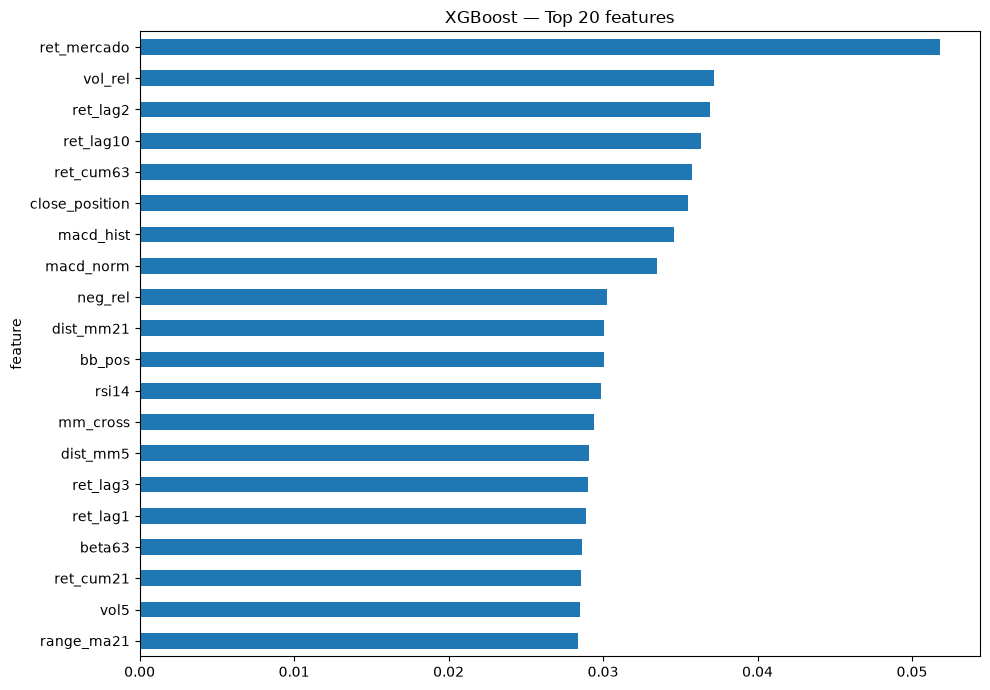

In [6]:
imp = pd.DataFrame({
    'feature': FEATURES,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print("Top 15 features:")
print(imp.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 7))
imp.head(20).sort_values('importance').plot.barh(
    x='feature', y='importance', ax=ax, legend=False
)
ax.set_title('XGBoost — Top 20 features')
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import TimeSeriesSplit

# Esquema: 4 janelas de treino crescente, sempre prevendo o próximo trimestre
# (usa TimeSeriesSplit em cima dos dias únicos, não das linhas)

dias = np.sort(df['DATA'].unique())
n_splits = 4

# Cria folds manuais: cada fold treina no passado, testa no "futuro imediato"
resultados = []

for i in range(n_splits):
    # Fatia 15% do total pra teste em cada fold, com avanço
    tam_teste = len(dias) // (n_splits + 2)
    inicio_teste = len(dias) - (n_splits - i) * tam_teste
    fim_teste = inicio_teste + tam_teste
    
    if inicio_teste <= 63:  # precisa de pelo menos 63 dias de treino
        continue
    
    data_treino_fim = dias[inicio_teste - 1]
    data_teste_ini  = dias[inicio_teste]
    data_teste_fim  = dias[min(fim_teste - 1, len(dias) - 1)]
    
    tr = df[df['DATA'] <= data_treino_fim]
    te = df[(df['DATA'] >= data_teste_ini) & (df['DATA'] <= data_teste_fim)]
    
    if len(te) < 100:
        continue
    
    X_tr_f, y_tr_f = tr[FEATURES], tr['target_bin']
    X_te_f, y_te_f = te[FEATURES], te['target_bin']
    
    pw = (y_tr_f == 0).sum() / (y_tr_f == 1).sum()
    
    m = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=20,
        reg_alpha=0.1, reg_lambda=1.0,
        scale_pos_weight=pw,
        objective='binary:logistic', eval_metric='auc',
        tree_method='hist', random_state=42, n_jobs=-1,
    )
    m.fit(X_tr_f, y_tr_f, verbose=False)
    
    prob = m.predict_proba(X_te_f)[:, 1]
    pred = m.predict(X_te_f)
    ic, _ = spearmanr(prob, te['target'].values)
    
    resultados.append({
        'fold': i + 1,
        'treino_fim': data_treino_fim,
        'teste_ini': data_teste_ini,
        'teste_fim': data_teste_fim,
        'n_treino': len(tr),
        'n_teste': len(te),
        'acuracia': accuracy_score(y_te_f, pred),
        'auc': roc_auc_score(y_te_f, prob),
        'ic': ic,
    })

res_df = pd.DataFrame(resultados)
print(res_df.to_string(index=False))
print(f"\nMÉDIA: acurácia={res_df['acuracia'].mean():.4f}  "
      f"AUC={res_df['auc'].mean():.4f}  IC={res_df['ic'].mean():.4f}")

 fold treino_fim  teste_ini  teste_fim  n_treino  n_teste  acuracia      auc       ic
    2 2024-08-14 2024-08-15 2024-09-26      4602     1504  0.497340 0.504039 0.025606
    3 2024-09-26 2024-09-27 2024-11-08      6106     1488  0.514785 0.519082 0.050085
    4 2024-11-08 2024-11-11 2024-12-27      7594     1488  0.518817 0.534876 0.071902

MÉDIA: acurácia=0.5103  AUC=0.5193  IC=0.0492


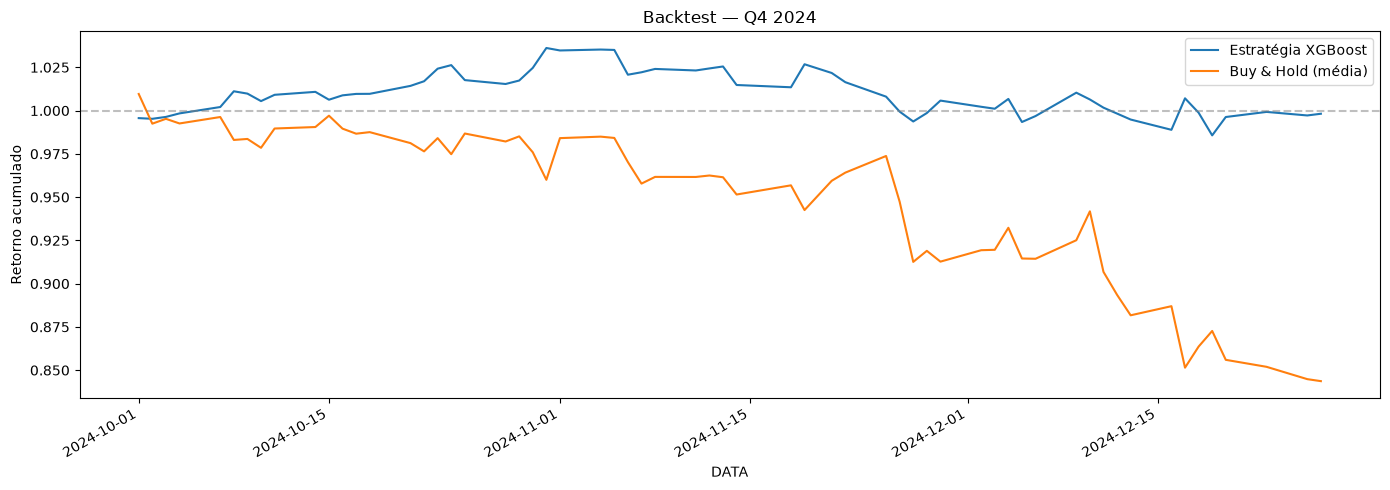

Total de sinais: 1879
Taxa de acerto direcional: 0.5003
Retorno acumulado estratégia: -0.0018
Retorno acumulado buy&hold:   -0.1563


In [8]:
# Usa o modelo do Bloco 4 (split único: treino até 30/09, teste Q4)
teste_bt = teste.copy()
teste_bt['prob'] = y_prob_te

# Sinais
teste_bt['sinal'] = 0
teste_bt.loc[teste_bt['prob'] > 0.55, 'sinal'] = 1   # long
teste_bt.loc[teste_bt['prob'] < 0.45, 'sinal'] = -1  # short

# P&L por trade (retorno do próximo dia × sinal)
# OBS: só "acerta" se retorno_real × sinal > 0
teste_bt['pnl'] = teste_bt['sinal'] * teste_bt['target']

# Resultado por dia
pnl_diario = teste_bt.groupby('DATA').agg(
    n_trades=('sinal', lambda x: (x != 0).sum()),
    pnl_medio=('pnl', 'mean'),
    pnl_total=('pnl', 'sum'),
).reset_index()

# Retorno da carteira (assume capital distribuído entre os trades do dia)
pnl_diario['ret_estrategia'] = pnl_diario['pnl_medio'].fillna(0)
pnl_diario['ret_buy_hold'] = teste_bt.groupby('DATA')['target'].mean().values

# Acumulado
pnl_diario['est_acum'] = (1 + pnl_diario['ret_estrategia']).cumprod()
pnl_diario['bh_acum']  = (1 + pnl_diario['ret_buy_hold']).cumprod()

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum',  ax=ax, label='Estratégia XGBoost')
pnl_diario.plot(x='DATA', y='bh_acum',   ax=ax, label='Buy & Hold (média)')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Métricas
n_trades_total = (teste_bt['sinal'] != 0).sum()
acertos = ((teste_bt['sinal'] != 0) & (teste_bt['pnl'] > 0)).sum()
taxa_acerto = acertos / n_trades_total if n_trades_total > 0 else 0

print(f"Total de sinais: {n_trades_total}")
print(f"Taxa de acerto direcional: {taxa_acerto:.4f}")
print(f"Retorno acumulado estratégia: {pnl_diario['est_acum'].iloc[-1] - 1:+.4f}")
print(f"Retorno acumulado buy&hold:   {pnl_diario['bh_acum'].iloc[-1] - 1:+.4f}")

In [9]:
probs_tr = model.predict_proba(X_tr)[:, 1]

thresholds = np.arange(0.50, 0.65, 0.01)
resultados_th = []

for th in thresholds:
    pred_th = (probs_tr > th).astype(int)
    if pred_th.sum() < 10:
        continue
    acc = accuracy_score(y_tr, pred_th)
    prec = precision_score(y_tr, pred_th, zero_division=0)
    rec = recall_score(y_tr, pred_th, zero_division=0)
    resultados_th.append({'threshold': th, 'acc': acc, 'prec': prec, 'rec': rec})

th_df = pd.DataFrame(resultados_th)
print(th_df.to_string(index=False))

 threshold      acc     prec      rec
      0.50 0.746211 0.728932 0.743737
      0.51 0.746533 0.742797 0.715640
      0.52 0.744276 0.755797 0.684157
      0.53 0.739439 0.768459 0.648274
      0.54 0.737182 0.785345 0.616791
      0.55 0.731538 0.798518 0.583615
      0.56 0.723960 0.812689 0.546378
      0.57 0.716866 0.827681 0.512187
      0.58 0.710255 0.841701 0.482397
      0.59 0.705579 0.860614 0.455653
      0.60 0.695743 0.873338 0.422478
      0.61 0.685424 0.882532 0.391672
      0.62 0.673976 0.889632 0.360190
      0.63 0.658820 0.896030 0.320921
      0.64 0.647694 0.902618 0.291808
      0.65 0.636891 0.910047 0.263710


Bloco refatorado — target relativo + sem scale_pos_weight + long-only 🚀

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                              recall_score, f1_score)
from xgboost import XGBClassifier

df = pd.read_parquet('dataset_modelagem.parquet')

# Target relativo binário: bate o mercado (1) ou não bate (0)?
df['target_rel_bin'] = (df['target_rel'] > 0).astype(int)

print("Balanceamento do target_rel_bin:")
print(df['target_rel_bin'].value_counts(normalize=True))
print(f"\nShape: {df.shape}")

Balanceamento do target_rel_bin:
target_rel_bin
1    0.501982
0    0.498018
Name: proportion, dtype: float64

Shape: (9082, 40)


In [11]:
FEATURES = [
    'ret_lag1','ret_lag2','ret_lag3','ret_lag5','ret_lag10','ret_lag21',
    'ret_cum5','ret_cum21','ret_cum63',
    'vol5','vol21','vol63','vol_ratio','range','range_ma21',
    'dist_mm5','dist_mm21','dist_mm63','mm_cross','bb_pos',
    'rsi14','macd_norm','macd_hist',
    'vol_rel','log_vol','neg_rel','close_position',
    'ret_rank','vol_rel_rank','rsi_rank','ret_rel','ret_mercado','beta63',
]

# Anti-leakage
for f in ['target','target_bin','target_rel','target_rel_bin','ret','ret_adj']:
    assert f not in FEATURES, f"❌ LEAKAGE: {f} em FEATURES!"

print(f"✅ {len(FEATURES)} features, sem leakage")

df = df.sort_values('DATA').reset_index(drop=True)

✅ 33 features, sem leakage


In [12]:
CORTE = '2024-10-01'

treino = df[df['DATA'] <  CORTE].copy()
teste  = df[df['DATA'] >= CORTE].copy()

X_tr = treino[FEATURES]
y_tr = treino['target_rel_bin']
X_te = teste[FEATURES]
y_te = teste['target_rel_bin']

model = XGBClassifier(
    n_estimators=500,
    max_depth=3,               # raso
    learning_rate=0.02,        # baixo
    subsample=0.7,
    colsample_bytree=0.7,
    min_child_weight=50,       # rígido contra overfit
    reg_alpha=0.5,
    reg_lambda=2.0,
    # scale_pos_weight REMOVIDO ✂️
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
)

model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_te, y_te)],
    verbose=False,
)

y_prob_te = model.predict_proba(X_te)[:, 1]
y_prob_tr = model.predict_proba(X_tr)[:, 1]

print("=== DISTRIBUIÇÃO DAS PROBABILIDADES ===")
print(f"Treino: min={y_prob_tr.min():.3f}  med={np.median(y_prob_tr):.3f}  max={y_prob_tr.max():.3f}")
print(f"Teste:  min={y_prob_te.min():.3f}  med={np.median(y_prob_te):.3f}  max={y_prob_te.max():.3f}")

print("\n=== MÉTRICAS NO TESTE ===")
print(f"AUC:       {roc_auc_score(y_te, y_prob_te):.4f}")
print(f"Acurácia:  {accuracy_score(y_te, (y_prob_te > 0.5).astype(int)):.4f}")

# IC: correlação entre prob prevista e retorno relativo REAL
ic, pval = spearmanr(y_prob_te, teste['target_rel'].values)
print(f"IC (Spearman prob × target_rel): {ic:.4f}  (p={pval:.4f})")

=== DISTRIBUIÇÃO DAS PROBABILIDADES ===
Treino: min=0.282  med=0.503  max=0.708
Teste:  min=0.283  med=0.498  max=0.722

=== MÉTRICAS NO TESTE ===
AUC:       0.5128
Acurácia:  0.4997
IC (Spearman prob × target_rel): 0.0360  (p=0.0531)


In [13]:
# Split do TREINO: 80% fit, 20% validação (cronológico)
corte_val = treino['DATA'].quantile(0.8, interpolation='nearest')
tr_fit = treino[treino['DATA'] < corte_val]
tr_val = treino[treino['DATA'] >= corte_val]

print(f"Fit:  {len(tr_fit)}  ({tr_fit['DATA'].min().date()} → {tr_fit['DATA'].max().date()})")
print(f"Val:  {len(tr_val)}  ({tr_val['DATA'].min().date()} → {tr_val['DATA'].max().date()})")

# Treina modelo só no fit
m_val = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
m_val.fit(tr_fit[FEATURES], tr_fit['target_rel_bin'], verbose=False)

prob_val = m_val.predict_proba(tr_val[FEATURES])[:, 1]

# Varre thresholds e escolhe o que maximiza IC na validação
thresholds = np.arange(0.50, 0.65, 0.005)
resultados = []
for th in thresholds:
    # Long-only: sinal = 1 quando prob > th
    mask = prob_val > th
    if mask.sum() < 30:
        continue
    # "Retorno" da estratégia: pega o target_rel real onde deu sinal
    ret_estrategia = tr_val.loc[mask, 'target_rel'].mean()
    sharpe = tr_val.loc[mask, 'target_rel'].mean() / (tr_val.loc[mask, 'target_rel'].std() + 1e-9)
    acerto = (tr_val.loc[mask, 'target_rel'] > 0).mean()
    resultados.append({
        'threshold': th,
        'n_sinais': mask.sum(),
        'ret_medio': ret_estrategia,
        'sharpe_por_trade': sharpe,
        'taxa_acerto': acerto,
    })

res_th = pd.DataFrame(resultados)
print("\nThresholds avaliados na validação:")
print(res_th.to_string(index=False))

# Escolhe o melhor por Sharpe (ou retorno médio)
melhor = res_th.sort_values('sharpe_por_trade', ascending=False).iloc[0]
TH_OTIMO = melhor['threshold']
print(f"\n✅ Threshold ótimo (validação): {TH_OTIMO:.3f}")
print(f"   n_sinais={int(melhor['n_sinais'])}  ret_medio={melhor['ret_medio']:.5f}  "
      f"sharpe={melhor['sharpe_por_trade']:.4f}  acerto={melhor['taxa_acerto']:.4f}")

Fit:  4945  (2024-04-03 → 2024-08-23)
Val:  1257  (2024-08-26 → 2024-09-30)

Thresholds avaliados na validação:
 threshold  n_sinais  ret_medio  sharpe_por_trade  taxa_acerto
     0.500       609   0.000052          0.002897     0.509031
     0.505       570   0.000179          0.010942     0.508772
     0.510       543   0.000203          0.012267     0.506446
     0.515       511   0.000346          0.020616     0.514677
     0.520       476   0.000674          0.041065     0.521008
     0.525       439   0.000834          0.049788     0.526196
     0.530       399   0.000283          0.019847     0.516291
     0.535       360   0.000255          0.017705     0.513889
     0.540       317   0.000387          0.027332     0.514196
     0.545       273  -0.000025         -0.002013     0.520147
     0.550       250   0.000124          0.010009     0.528000
     0.555       219   0.000680          0.055403     0.547945
     0.560       196   0.000708          0.056493     0.551020
     0

In [14]:
dias = np.sort(df['DATA'].unique())
n_splits = 4
resultados_wf = []

for i in range(n_splits):
    tam_teste = len(dias) // (n_splits + 2)
    inicio_teste = len(dias) - (n_splits - i) * tam_teste
    fim_teste = min(inicio_teste + tam_teste, len(dias))
    
    if inicio_teste <= 63:
        continue
    
    data_treino_fim = dias[inicio_teste - 1]
    data_teste_ini  = dias[inicio_teste]
    data_teste_fim  = dias[fim_teste - 1]
    
    tr = df[df['DATA'] <= data_treino_fim]
    te = df[(df['DATA'] >= data_teste_ini) & (df['DATA'] <= data_teste_fim)]
    
    if len(te) < 100:
        continue
    
    m = XGBClassifier(
        n_estimators=500, max_depth=3, learning_rate=0.02,
        subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
        reg_alpha=0.5, reg_lambda=2.0,
        objective='binary:logistic', eval_metric='auc',
        tree_method='hist', random_state=42, n_jobs=-1,
    )
    m.fit(tr[FEATURES], tr['target_rel_bin'], verbose=False)
    
    prob = m.predict_proba(te[FEATURES])[:, 1]
    ic, _ = spearmanr(prob, te['target_rel'].values)
    
    resultados_wf.append({
        'fold': i + 1,
        'treino_fim': data_treino_fim,
        'teste_ini': data_teste_ini,
        'teste_fim': data_teste_fim,
        'n_treino': len(tr),
        'n_teste': len(te),
        'auc': roc_auc_score(te['target_rel_bin'], prob),
        'ic': ic,
    })

wf = pd.DataFrame(resultados_wf)
print(wf.to_string(index=False))
print(f"\nMÉDIA: AUC={wf['auc'].mean():.4f}  IC={wf['ic'].mean():.4f}  "
      f"(std AUC={wf['auc'].std():.4f}, std IC={wf['ic'].std():.4f})")

 fold treino_fim  teste_ini  teste_fim  n_treino  n_teste      auc        ic
    2 2024-08-14 2024-08-15 2024-09-26      4602     1504 0.500119 -0.015311
    3 2024-09-26 2024-09-27 2024-11-08      6106     1488 0.503673  0.026021
    4 2024-11-08 2024-11-11 2024-12-27      7594     1488 0.529970  0.046894

MÉDIA: AUC=0.5113  IC=0.0192  (std AUC=0.0163, std IC=0.0317)


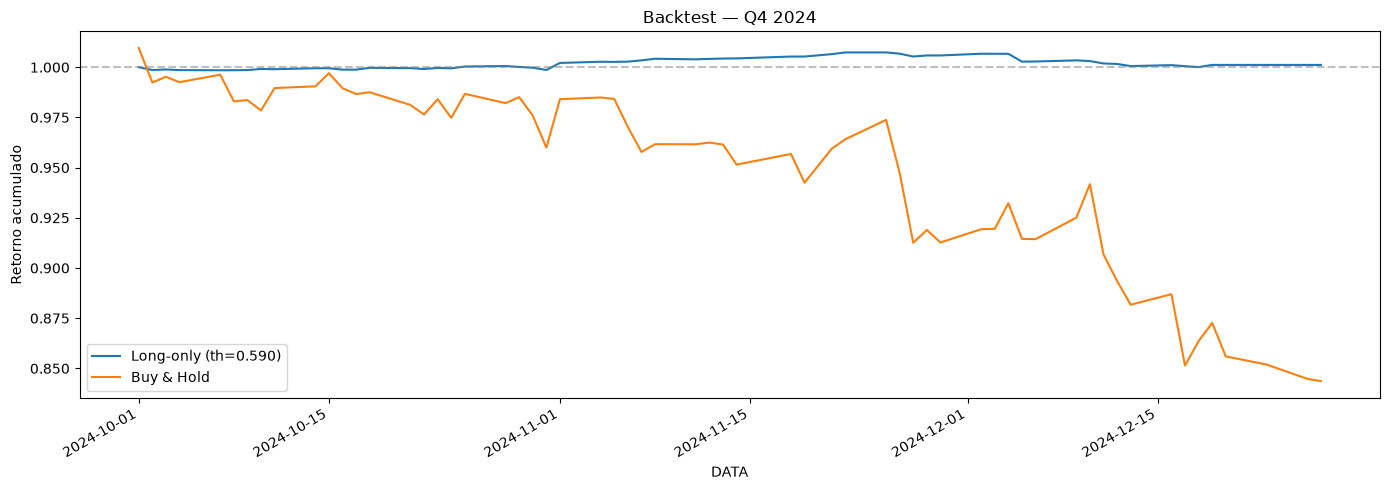

Dias totais no teste: 60
Total de sinais long: 169  (5.9% das linhas)
Taxa de acerto long: 0.4793

Retorno acumulado estratégia: +0.0012  (+0.12%)
Retorno acumulado buy&hold:   -0.1563  (-15.63%)

Sharpe anualizado estratégia: 0.35
Sharpe anualizado buy&hold:   -3.28


In [15]:
# Reusa o modelo do Bloco 2
teste_bt = teste.copy()
teste_bt['prob'] = y_prob_te

# Estratégia: long-only com threshold calibrado
teste_bt['sinal'] = (teste_bt['prob'] > TH_OTIMO).astype(int)

# P&L: usa retorno ABSOLUTO (target), não relativo — você quer dinheiro, não alpha
teste_bt['pnl'] = teste_bt['sinal'] * teste_bt['target']

# P&L diário
pnl_diario = teste_bt.groupby('DATA').agg(
    n_sinais=('sinal', 'sum'),
    ret_estrategia=('pnl', 'mean'),
    ret_bh=('target', 'mean'),
).reset_index()

pnl_diario['est_acum'] = (1 + pnl_diario['ret_estrategia']).cumprod()
pnl_diario['bh_acum']  = (1 + pnl_diario['ret_bh']).cumprod()

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum', ax=ax, label=f'Long-only (th={TH_OTIMO:.3f})')
pnl_diario.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Métricas
ret_est = pnl_diario['est_acum'].iloc[-1] - 1
ret_bh  = pnl_diario['bh_acum'].iloc[-1] - 1
sharpe_est = pnl_diario['ret_estrategia'].mean() / (pnl_diario['ret_estrategia'].std() + 1e-9) * np.sqrt(252)
sharpe_bh  = pnl_diario['ret_bh'].mean() / (pnl_diario['ret_bh'].std() + 1e-9) * np.sqrt(252)

n_sinais = teste_bt['sinal'].sum()
acertos = ((teste_bt['sinal'] == 1) & (teste_bt['target'] > 0)).sum()
taxa_acerto = acertos / n_sinais if n_sinais > 0 else 0

print(f"Dias totais no teste: {len(pnl_diario)}")
print(f"Total de sinais long: {n_sinais}  ({n_sinais/len(teste_bt)*100:.1f}% das linhas)")
print(f"Taxa de acerto long: {taxa_acerto:.4f}")
print(f"\nRetorno acumulado estratégia: {ret_est:+.4f}  ({ret_est*100:+.2f}%)")
print(f"Retorno acumulado buy&hold:   {ret_bh:+.4f}  ({ret_bh*100:+.2f}%)")
print(f"\nSharpe anualizado estratégia: {sharpe_est:.2f}")
print(f"Sharpe anualizado buy&hold:   {sharpe_bh:.2f}")

In [16]:
# Mapa setorial (edite conforme necessário)
SETOR_MAP = {
    # Financeiro
    'ITUB4': 'Financeiro', 'BBDC4': 'Financeiro', 'BBAS3': 'Financeiro',
    'B3SA3': 'Financeiro', 'BPAC11': 'Financeiro', 'SANB11': 'Financeiro',
    # Energia / Petróleo
    'PETR4': 'Petróleo', 'PETR3': 'Petróleo', 'PRIO3': 'Petróleo',
    'ELET3': 'Energia', 'CMIG4': 'Energia', 'SBSP3': 'Energia',
    # Mineração / Siderurgia
    'VALE3': 'Mineração', 'GGBR4': 'Siderurgia', 'CSNA3': 'Siderurgia',
    # Consumo
    'ABEV3': 'Bebidas', 'LREN3': 'Varejo', 'MGLU3': 'Varejo',
    'ASAI3': 'Varejo', 'RADL3': 'Saúde',
    # Indústria
    'WEGE3': 'Industrial', 'EMBR3': 'Aeroespacial', 'RENT3': 'Aluguel',
    'RAIL3': 'Logística', 'CCRO3': 'Logística',
    # Papel / Celulose
    'SUZB3': 'Papel', 'KLBN11': 'Papel',
    # Saúde
    'HAPV3': 'Saúde', 'RDOR3': 'Saúde', 'HYPE3': 'Saúde',
    # Construção
    'MRVE3': 'Construção', 'CYRE3': 'Construção', 'EZTC3': 'Construção',
    # Outros
    'AZUL4': 'Aérea', 'GOLL4': 'Aérea',
    'NTCO3': 'Cosméticos', 'BRFS3': 'Alimentos', 'JBSS3': 'Alimentos',
    'TOTS3': 'Tecnologia', 'LWSA3': 'Tecnologia',
    # ETFs (marcar como ETF)
    'BOVA11': 'ETF', 'IBOV11': 'ETF',
}

df['setor'] = df['CODNEG'].map(SETOR_MAP)

# Checar quantos ficaram sem setor
faltando = df[df['setor'].isna()]['CODNEG'].unique()
print(f"Tickers sem setor mapeado: {list(faltando)}")
print(f"Tickers com setor: {df['setor'].notna().sum()}")

Tickers sem setor mapeado: ['BBSE3', 'RRRP3', 'TIMS3', 'UGPA3', 'VBBR3', 'SMAL11', 'ENEV3', 'CSAN3', 'ENGI11', 'EQTL3', 'CPLE6', 'ITSA4', 'MULT3', 'BOVV11', 'VIVT3']
Tickers com setor: 6354


In [17]:
import yfinance as yf
import pandas as pd
import numpy as np

# Ativos macro
MACRO_TICKERS = {
    '^BVSP': 'ibov',        # Ibovespa
    'BRL=X': 'dolar',       # USD/BRL
    '^VIX': 'vix',          # VIX global (risco)
    '^TNX': 'juro_usa',     # Treasury 10Y (juro americano)
}

# Baixa tudo de uma vez
macro_raw = yf.download(
    list(MACRO_TICKERS.keys()),
    start='2024-01-01',
    end='2025-01-01',
    progress=False,
)['Close']

# Renomeia colunas
macro_raw.columns = [MACRO_TICKERS[c] for c in macro_raw.columns]
macro_raw = macro_raw.reset_index().rename(columns={'Date': 'DATA'})

print(macro_raw.head())
print(f"\nShape macro: {macro_raw.shape}")

        DATA   dolar      ibov  juro_usa    vix
0 2024-01-01  4.8505       NaN       NaN    NaN
1 2024-01-02  4.8524  132697.0     3.946  13.20
2 2024-01-03  4.9225  132834.0     3.907  14.04
3 2024-01-04  4.9192  131226.0     3.991  14.13
4 2024-01-05  4.8956  132023.0     4.042  13.35

Shape macro: (262, 5)


In [19]:
df['DATA'] = pd.to_datetime(df['DATA']).dt.tz_localize(None).astype('datetime64[ns]')
macro_raw['DATA'] = pd.to_datetime(macro_raw['DATA']).dt.tz_localize(None).astype('datetime64[ns]')

# Merge: para cada linha do df, pega o último valor macro <= DATA
df = pd.merge_asof(
    df,
    macro_raw,
    on='DATA',
    direction='backward',   # pega o último dado disponível até aquela data
)

# Checa NaN
print("NaN nas colunas macro:")
print(df[['ibov','dolar','vix','juro_usa']].isna().sum())
print(f"\nShape após merge: {df.shape}")

NaN nas colunas macro:
ibov          0
dolar         0
vix         243
juro_usa    243
dtype: int64

Shape após merge: (9082, 45)


In [20]:
# 1) Diagnóstico rápido
print("Datas com VIX NaN (amostra):")
datas = df[df['vix'].isna()]['DATA'].dt.strftime('%Y-%m-%d').unique()
print(datas[:10], '...', datas[-10:] if len(datas) > 10 else '')

# 2) Forward fill
for col in ['vix', 'juro_usa']:
    df[col] = df[col].ffill()

# 3) Verifica
print("\nNaN após ffill:")
print(df[['ibov','dolar','vix','juro_usa']].isna().sum())

# 4) Se ainda houver NaN (nos primeiros dias), dropa essas linhas
n_antes = len(df)
df = df.dropna(subset=['ibov','dolar','vix','juro_usa']).reset_index(drop=True)
print(f"\nLinhas removidas: {n_antes - len(df)}")
print(f"Shape final: {df.shape}")

Datas com VIX NaN (amostra):
<ArrowStringArray>
['2024-05-27', '2024-06-19', '2024-07-04', '2024-09-02', '2024-11-28']
Length: 5, dtype: str ... 

NaN após ffill:
ibov        0
dolar       0
vix         0
juro_usa    0
dtype: int64

Linhas removidas: 0
Shape final: (9082, 45)


In [21]:
# Garante que setor foi mapeado
if 'setor' not in df.columns:
    print("⚠️ Rode o Bloco 1 do post anterior pra criar a coluna 'setor'")
else:
    print("Setores presentes:", df['setor'].value_counts().to_dict())

# Features setoriais
df['ret_setor']     = df.groupby(['DATA','setor'])['ret'].transform('mean')
df['ret_rel_setor'] = df['ret'] - df['ret_setor']
df['vol_setor']     = df.groupby(['DATA','setor'])['vol21'].transform('mean')

# One-hot do setor
setor_dummies = pd.get_dummies(df['setor'], prefix='setor', drop_first=True).astype(int)
df = pd.concat([df, setor_dummies], axis=1)

print(f"\nSetores codificados: {setor_dummies.shape[1]} dummies")
print(df[['ret_setor','ret_rel_setor','vol_setor']].describe())

Setores presentes: {'Financeiro': 933, 'Saúde': 748, 'Energia': 561, 'Petróleo': 561, 'Varejo': 559, 'Alimentos': 374, 'Construção': 374, 'Bebidas': 187, 'Siderurgia': 187, 'Industrial': 187, 'Aeroespacial': 187, 'Cosméticos': 187, 'Logística': 187, 'Aluguel': 187, 'ETF': 187, 'Tecnologia': 187, 'Aérea': 187, 'Mineração': 187, 'Papel': 187}

Setores codificados: 18 dummies
         ret_setor  ret_rel_setor    vol_setor
count  6354.000000   6.354000e+03  6354.000000
mean     -0.001001   1.092051e-21     0.019933
std       0.020294   1.046523e-02     0.009256
min      -0.276253  -1.700713e-01     0.004153
25%      -0.010692  -2.609186e-03     0.014094
50%      -0.000496   0.000000e+00     0.018078
75%       0.009468   2.774299e-03     0.023995
max       0.203143   9.752011e-02     0.108479


In [22]:
# Retornos macro
for col in ['ibov', 'dolar', 'vix', 'juro_usa']:
    df[f'{col}_ret']    = df[col].pct_change()
    df[f'{col}_vol21']  = df[f'{col}_ret'].rolling(21).std()

# Distâncias da MM
df['dolar_dist_mm21'] = (df['dolar'] / df['dolar'].rolling(21).mean()) - 1
df['ibov_dist_mm21']  = (df['ibov']  / df['ibov'].rolling(21).mean()) - 1

# Correlação dólar × ibov (regime de stress cambial)
df['corr_dolar_ibov'] = df['dolar_ret'].rolling(21).corr(df['ibov_ret'])

# Flag VIX alto
df['vix_alto'] = (df['vix'] > df['vix'].rolling(63).quantile(0.8)).astype(int)

print("Features macro criadas:")
print(df[['ibov_ret','dolar_ret','vix_ret','juro_usa_ret',
          'dolar_dist_mm21','ibov_dist_mm21','corr_dolar_ibov','vix_alto']].describe())

Features macro criadas:
          ibov_ret    dolar_ret      vix_ret  juro_usa_ret  dolar_dist_mm21  \
count  9081.000000  9081.000000  9081.000000   9081.000000      9062.000000   
mean     -0.000006     0.000022     0.000110      0.000008         0.000216   
std       0.001186     0.001258     0.015150      0.001990         0.003202   
min      -0.031484    -0.021832    -0.281566     -0.046278        -0.020814   
25%       0.000000     0.000000     0.000000      0.000000         0.000000   
50%       0.000000     0.000000     0.000000      0.000000         0.000000   
75%       0.000000     0.000000     0.000000      0.000000         0.000000   
max       0.018685     0.030427     0.740391      0.044434         0.028936   

       ibov_dist_mm21  corr_dolar_ibov     vix_alto  
count     9062.000000      3906.000000  9082.000000  
mean        -0.000061        -0.096774     0.085884  
std          0.003033         0.995434     0.280208  
min         -0.030030        -1.000000     0.000

In [26]:
FEATURES_BASE = [
    'ret_lag1','ret_lag2','ret_lag3','ret_lag5','ret_lag10','ret_lag21',
    'ret_cum5','ret_cum21','ret_cum63',
    'vol5','vol21','vol63','vol_ratio','range','range_ma21',
    'dist_mm5','dist_mm21','dist_mm63','mm_cross','bb_pos',
    'rsi14','macd_norm','macd_hist',
    'vol_rel','log_vol','neg_rel','close_position',
    'ret_rank','vol_rel_rank','rsi_rank','ret_rel','ret_mercado','beta63',
]

FEATURES_MACRO = [
    'ibov_ret','dolar_ret','vix_ret','juro_usa_ret',
    'ibov_vol21','dolar_vol21',
    'dolar_dist_mm21','ibov_dist_mm21',
    'corr_dolar_ibov','vix_alto',
]

FEATURES_SETOR = [
    'ret_setor','ret_rel_setor','vol_setor',
] + list(setor_dummies.columns)

FEATURES_TOTAL = FEATURES_BASE + FEATURES_MACRO + FEATURES_SETOR

# Anti-leakage
for f in ['target','target_bin','target_rel','target_rel_bin','ret','ibov','dolar','vix','juro_usa']:
    assert f not in FEATURES_TOTAL, f"❌ LEAKAGE: {f}"

print(f"Total de features: {len(FEATURES_TOTAL)}")

# ---------- TREINA MODELO NOVO ----------
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# Drop linhas com NaN nas novas features (primeiros dias)
df_model = df.dropna(subset=FEATURES_TOTAL + ['target_rel']).copy()
print(f"Shape após dropna: {df_model.shape}")

CORTE = '2024-10-01'
treino = df_model[df_model['DATA'] <  CORTE]
teste  = df_model[df_model['DATA'] >= CORTE]

model_novo = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_novo.fit(treino[FEATURES_TOTAL], treino['target_rel_bin'], verbose=False)

prob = model_novo.predict_proba(teste[FEATURES_TOTAL])[:, 1]
auc = roc_auc_score(teste['target_rel_bin'], prob)
ic, pval = spearmanr(prob, teste['target_rel'])

print("\n=== RESULTADO COM FEATURES NOVAS ===")
print(f"AUC: {auc:.4f}  (baseline: 0.5128)")
print(f"IC:  {ic:.4f}  (baseline: 0.0360)  p={pval:.4f}")

# Feature importance
imp_novo = pd.DataFrame({
    'feature': FEATURES_TOTAL,
    'importance': model_novo.feature_importances_,
}).sort_values('importance', ascending=False)

print("\nTop 20 features:")
print(imp_novo.head(20).to_string(index=False))

Total de features: 64
Shape após dropna: (2755, 78)

=== RESULTADO COM FEATURES NOVAS ===
AUC: 0.4891  (baseline: 0.5128)
IC:  -0.0115  (baseline: 0.0360)  p=0.7319

Top 20 features:
        feature  importance
      ret_lag10    0.028897
          vol21    0.028074
          rsi14    0.027668
      ret_cum63    0.027158
    dolar_vol21    0.027115
       rsi_rank    0.026828
     range_ma21    0.026789
      macd_norm    0.026177
dolar_dist_mm21    0.025811
         beta63    0.025713
          vol63    0.025477
        neg_rel    0.025477
       ret_rank    0.025408
        ret_rel    0.025251
corr_dolar_ibov    0.025222
     ibov_vol21    0.024732
       ret_lag1    0.024615
      ret_lag21    0.024574
      dist_mm63    0.024523
      ret_setor    0.024394


In [24]:
faltando = df[['corr_dolar_ibov','ret_setor','vol_setor']].isna().sum(axis=1)
print("Linhas com 0 NaN:", (faltando == 0).sum())
print("Linhas com 1+ NaN:", (faltando > 0).sum())
print("\nDistribuição de NaN por linha:")
print(faltando.value_counts().sort_index())

Linhas com 0 NaN: 2755
Linhas com 1+ NaN: 6327

Distribuição de NaN por linha:
0    2755
1    3599
2    1151
3    1577
Name: count, dtype: int64


In [25]:
# ---------- CORREÇÃO DAS FEATURES PROBLEMÁTICAS ----------

# 1) corr_dolar_ibov com min_periods
df['corr_dolar_ibov'] = (
    df['dolar_ret'].rolling(21, min_periods=10).corr(df['ibov_ret'])
)

# 2) Features setoriais com ffill
df['ret_para_setor'] = df.groupby('CODNEG')['ret'].ffill()
df['ret_setor']     = df.groupby(['DATA','setor'])['ret_para_setor'].transform('mean')
df['ret_rel_setor'] = df['ret'] - df['ret_setor']
df['vol_setor']     = df.groupby(['DATA','setor'])['vol21'].transform('mean')
df = df.drop(columns=['ret_para_setor'])

# 3) Checa quantos NaN cada feature crítica tem agora
criticas = ['corr_dolar_ibov','ret_setor','ret_rel_setor','vol_setor']
print("NaN por feature crítica:")
print(df[criticas].isna().sum())

# ---------- DROPNA INTELIGENTE ----------
df_model = df[df[FEATURES_TOTAL].isna().sum(axis=1) <= 5].copy()

# Preenche NaN restantes com ffill por ticker
for f in FEATURES_TOTAL:
    df_model[f] = df_model.groupby('CODNEG')[f].ffill()

# Depois remove só o que ainda é NaN
df_model = df_model.dropna(subset=['target_rel'] + FEATURES_TOTAL).copy()

print(f"\nShape após tratamento: {df_model.shape}")

NaN por feature crítica:
corr_dolar_ibov    5176
ret_setor          2728
ret_rel_setor      2728
vol_setor          2728
dtype: int64

Shape após tratamento: (6269, 78)


In [27]:
CORTE = '2024-10-01'
treino = df_model[df_model['DATA'] <  CORTE]
teste  = df_model[df_model['DATA'] >= CORTE]

print(f"Treino: {len(treino)}  Teste: {len(teste)}")

model_novo = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_novo.fit(treino[FEATURES_TOTAL], treino['target_rel_bin'], verbose=False)

prob = model_novo.predict_proba(teste[FEATURES_TOTAL])[:, 1]
auc = roc_auc_score(teste['target_rel_bin'], prob)
ic, pval = spearmanr(prob, teste['target_rel'])

print(f"\nAUC: {auc:.4f}  (baseline: 0.5128)")
print(f"IC:  {ic:.4f}  (baseline: 0.0360)  p={pval:.4f}")

Treino: 1859  Teste: 896

AUC: 0.4891  (baseline: 0.5128)
IC:  -0.0115  (baseline: 0.0360)  p=0.7319


In [28]:
print("len(df):", len(df) if 'df' in dir() else 'não definido')
print("len(df_model):", len(df_model) if 'df_model' in dir() else 'não definido')
print("len(teste):", len(teste) if 'teste' in dir() else 'não definido')
print("\nAUC anterior calculado em quantas linhas?", len(teste) if 'teste' in dir() else '?')

len(df): 9082
len(df_model): 2755
len(teste): 896

AUC anterior calculado em quantas linhas? 896


In [29]:
# Rastreia a origem de df_model
print("Shape atual de df_model:", df_model.shape)
print("Colunas de df_model:", len(df_model.columns))

# Chuta: quais colunas novas (macro/setor) existem em df_model?
novas = ['ibov_ret','dolar_ret','ret_setor','ret_rel_setor','corr_dolar_ibov','vix_alto']
for c in novas:
    if c in df_model.columns:
        print(f"  ✓ {c}")
    else:
        print(f"  ✗ {c}  ← AUSENTE")

Shape atual de df_model: (2755, 78)
Colunas de df_model: 78
  ✓ ibov_ret
  ✓ dolar_ret
  ✓ ret_setor
  ✓ ret_rel_setor
  ✓ corr_dolar_ibov
  ✓ vix_alto


In [30]:
nans = df[FEATURES_TOTAL].isna().sum().sort_values(ascending=False)
print(nans.head(15))

corr_dolar_ibov    5176
vol_setor          2728
ret_rel_setor      2728
ret_setor          2728
ibov_vol21           21
dolar_vol21          21
ibov_dist_mm21       20
dolar_dist_mm21      20
dolar_ret             1
vix_ret               1
juro_usa_ret          1
ibov_ret              1
ret_lag1              0
ret_lag2              0
ret_lag3              0
dtype: int64


In [31]:
# ============================================================
# VERSÃO FINAL — SEM as features problemáticas
# ============================================================
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
from scipy.stats import spearmanr

# Features a REMOVER
FEATURES_REMOVER = ['corr_dolar_ibov', 'ret_setor', 'ret_rel_setor', 'vol_setor']

FEATURES_TOTAL_V2 = [f for f in FEATURES_TOTAL if f not in FEATURES_REMOVER]
print(f"Features: {len(FEATURES_TOTAL)} → {len(FEATURES_TOTAL_V2)}")

# Filtra linhas com NaN
n_antes = len(df)
df_model_v2 = df[df[FEATURES_TOTAL_V2].isna().sum(axis=1) <= 5].copy()
print(f"Linhas removidas pelo filtro (<=5 NaN): {n_antes - len(df_model_v2)}")

# Preenche NaN residuais por ticker
for f in FEATURES_TOTAL_V2:
    df_model_v2[f] = df_model_v2.groupby('CODNEG')[f].ffill()

df_model_v2 = df_model_v2.dropna(subset=['target_rel'] + FEATURES_TOTAL_V2).copy()
print(f"Shape final: {df_model_v2.shape}")

# Split temporal
CORTE = '2024-10-01'
treino = df_model_v2[df_model_v2['DATA'] <  CORTE]
teste  = df_model_v2[df_model_v2['DATA'] >= CORTE]
print(f"Treino: {len(treino)}  |  Teste: {len(teste)}")

# Treina
model_final = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_final.fit(treino[FEATURES_TOTAL_V2], treino['target_rel_bin'], verbose=False)

prob = model_final.predict_proba(teste[FEATURES_TOTAL_V2])[:, 1]
auc = roc_auc_score(teste['target_rel_bin'], prob)
ic, pval = spearmanr(prob, teste['target_rel'])

print(f"\n=== RESULTADO FINAL ===")
print(f"AUC: {auc:.4f}  (baseline 33 feat: 0.5128)")
print(f"IC:  {ic:.4f}  (baseline 33 feat: 0.0360)  p={pval:.4f}")

# Feature importance
imp_final = pd.DataFrame({
    'feature': FEATURES_TOTAL_V2,
    'importance': model_final.feature_importances_,
}).sort_values('importance', ascending=False)

print("\nTop 20 features:")
print(imp_final.head(20).to_string(index=False))

Features: 64 → 60
Linhas removidas pelo filtro (<=5 NaN): 1
Shape final: (9061, 78)
Treino: 6181  |  Teste: 2880

=== RESULTADO FINAL ===
AUC: 0.5171  (baseline 33 feat: 0.5128)
IC:  0.0423  (baseline 33 feat: 0.0360)  p=0.0231

Top 20 features:
       feature  importance
   ret_mercado    0.031189
       log_vol    0.027977
    range_ma21    0.027629
          vol5    0.027548
         vol21    0.027511
        beta63    0.027123
      rsi_rank    0.026942
close_position    0.026871
         vol63    0.026369
      ret_lag2    0.026214
     ret_lag10    0.026137
      ret_lag1    0.026109
       neg_rel    0.026072
     dist_mm21    0.025918
       vol_rel    0.025674
      dist_mm5    0.025610
    ibov_vol21    0.025453
      ret_cum5    0.025100
     ret_cum63    0.025016
   dolar_vol21    0.024857


In [32]:
# ============================================================
# WALK-FORWARD com o modelo final
# ============================================================
dias = np.sort(df_model_v2['DATA'].unique())
n_splits = 4
resultados_wf = []

for i in range(n_splits):
    tam_teste = len(dias) // (n_splits + 2)
    inicio_teste = len(dias) - (n_splits - i) * tam_teste
    fim_teste = min(inicio_teste + tam_teste, len(dias))
    
    if inicio_teste <= 63:
        continue
    
    data_treino_fim = dias[inicio_teste - 1]
    data_teste_ini  = dias[inicio_teste]
    data_teste_fim  = dias[fim_teste - 1]
    
    tr = df_model_v2[df_model_v2['DATA'] <= data_treino_fim]
    te = df_model_v2[(df_model_v2['DATA'] >= data_teste_ini) & 
                     (df_model_v2['DATA'] <= data_teste_fim)]
    
    if len(te) < 100:
        continue
    
    m = XGBClassifier(
        n_estimators=500, max_depth=3, learning_rate=0.02,
        subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
        reg_alpha=0.5, reg_lambda=2.0,
        objective='binary:logistic', eval_metric='auc',
        tree_method='hist', random_state=42, n_jobs=-1,
    )
    m.fit(tr[FEATURES_TOTAL_V2], tr['target_rel_bin'], verbose=False)
    
    prob = m.predict_proba(te[FEATURES_TOTAL_V2])[:, 1]
    ic, _ = spearmanr(prob, te['target_rel'])
    auc = roc_auc_score(te['target_rel_bin'], prob)
    
    resultados_wf.append({
        'fold': i + 1,
        'treino_fim': data_treino_fim,
        'teste_ini': data_teste_ini,
        'teste_fim': data_teste_fim,
        'n_treino': len(tr),
        'n_teste': len(te),
        'auc': auc,
        'ic': ic,
    })

wf_final = pd.DataFrame(resultados_wf)
print(wf_final.to_string(index=False))
print(f"\nMÉDIA: AUC={wf_final['auc'].mean():.4f} (±{wf_final['auc'].std():.4f})")
print(f"       IC={wf_final['ic'].mean():.4f}  (±{wf_final['ic'].std():.4f})")

 fold treino_fim  teste_ini  teste_fim  n_treino  n_teste      auc        ic
    2 2024-08-14 2024-08-15 2024-09-26      4581     1504 0.507424 -0.005648
    3 2024-09-26 2024-09-27 2024-11-08      6085     1488 0.507260  0.037000
    4 2024-11-08 2024-11-11 2024-12-27      7573     1488 0.538528  0.061055

MÉDIA: AUC=0.5177 (±0.0180)
       IC=0.0308  (±0.0338)


In [33]:
teste_bt = teste.copy()
teste_bt['prob'] = prob

# Threshold ótimo (você já tinha achado 0.59 antes, testa de novo)
# Como o modelo mudou, recalibra na validação do treino
corte_val = treino['DATA'].quantile(0.8, interpolation='nearest')
tr_fit = treino[treino['DATA'] < corte_val]
tr_val = treino[treino['DATA'] >= corte_val]

m_val = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
m_val.fit(tr_fit[FEATURES_TOTAL_V2], tr_fit['target_rel_bin'], verbose=False)
prob_val = m_val.predict_proba(tr_val[FEATURES_TOTAL_V2])[:, 1]

melhor_th, melhor_ret = 0.5, -999
for th in np.arange(0.50, 0.65, 0.01):
    mask = prob_val > th
    if mask.sum() < 30:
        continue
    ret_medio = tr_val.loc[mask, 'target'].mean()
    if ret_medio > melhor_ret:
        melhor_ret = ret_medio
        melhor_th = th

print(f"Threshold ótimo: {melhor_th:.3f}  (ret médio val: {melhor_ret:.5f})")

# Aplica no teste
teste_bt['sinal'] = (teste_bt['prob'] > melhor_th).astype(int)
teste_bt['pnl']   = teste_bt['sinal'] * teste_bt['target']

pnl_diario = teste_bt.groupby('DATA').agg(
    n_sinais=('sinal', 'sum'),
    ret_estrategia=('pnl', 'mean'),
    ret_bh=('target', 'mean'),
).reset_index()

pnl_diario['est_acum'] = (1 + pnl_diario['ret_estrategia']).cumprod()
pnl_diario['bh_acum']  = (1 + pnl_diario['ret_bh']).cumprod()

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum', ax=ax, label=f'Long-only (th={melhor_th:.2f})')
pnl_diario.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest final — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

ret_est = pnl_diario['est_acum'].iloc[-1] - 1
ret_bh  = pnl_diario['bh_acum'].iloc[-1] - 1
sharpe  = pnl_diario['ret_estrategia'].mean() / (pnl_diario['ret_estrategia'].std() + 1e-9) * np.sqrt(252)
n_trades = teste_bt['sinal'].sum()

print(f"\nSinais long: {n_trades} ({n_trades/len(teste_bt)*100:.1f}%)")
print(f"Retorno estratégia: {ret_est:+.2%}")
print(f"Retorno buy&hold:   {ret_bh:+.2%}")
print(f"Sharpe anualizado:  {sharpe:.2f}")

ValueError: Length of values (1488) does not match length of index (2880)

In [34]:
# ============================================================
# BACKTEST — retreina o modelo principal PRIMEIRO
# ============================================================

# Reusa treino/teste do split único (6181 / 2880)
# treino e teste já existem das células anteriores

model_final = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_final.fit(treino[FEATURES_TOTAL_V2], treino['target_rel_bin'], verbose=False)

# ⚠️ Agora prob tem o tamanho certo (2880)
prob_teste = model_final.predict_proba(teste[FEATURES_TOTAL_V2])[:, 1]
print(f"Shape prob: {prob_teste.shape}  |  Shape teste: {teste.shape}")

# Backtest
teste_bt = teste.copy()
teste_bt['prob'] = prob_teste  # ← usa prob_teste, não prob

Shape prob: (2880,)  |  Shape teste: (2880, 78)


Thresholds na validação:
 threshold  n_sinais  ret_medio    sharpe   acerto
      0.50       622  -0.001663 -0.091325 0.422830
      0.51       537  -0.001441 -0.077753 0.432030
      0.52       448  -0.001355 -0.070547 0.446429
      0.53       381  -0.000878 -0.045415 0.448819
      0.54       316  -0.001229 -0.075319 0.455696
      0.55       250  -0.001270 -0.079061 0.464000
      0.56       193  -0.001680 -0.111443 0.461140
      0.57       141  -0.001392 -0.089190 0.496454
      0.58       109  -0.000127 -0.008907 0.495413
      0.59        85  -0.000057 -0.004129 0.494118
      0.60        67   0.000383  0.027380 0.492537
      0.61        53   0.001685  0.119306 0.547170
      0.62        41  -0.000825 -0.077827 0.512195

✅ Threshold ótimo: 0.61  (n=53)


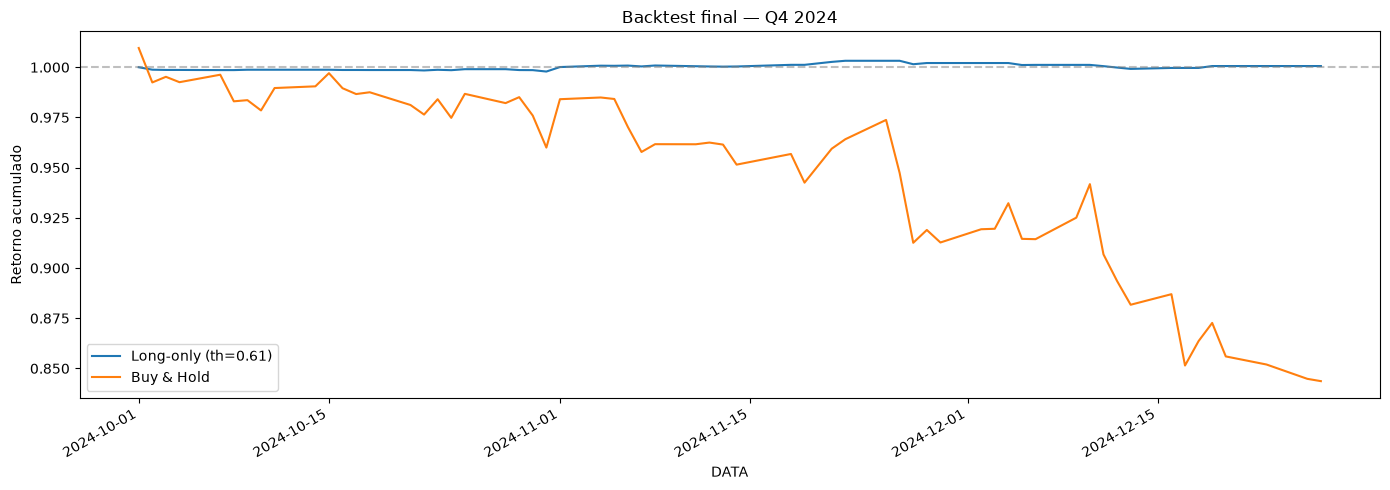


=== RESULTADO FINAL ===
Threshold: 0.61
Sinais long: 96  (3.3% das linhas)
Taxa de acerto long: 44.79%
Retorno estratégia:  +0.06%
Retorno buy&hold:    -15.63%
Sharpe estratégia:   0.29


In [35]:
# Threshold ótimo na validação do treino
corte_val = treino['DATA'].quantile(0.8, interpolation='nearest')
tr_fit = treino[treino['DATA'] < corte_val]
tr_val = treino[treino['DATA'] >= corte_val]

m_val = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
m_val.fit(tr_fit[FEATURES_TOTAL_V2], tr_fit['target_rel_bin'], verbose=False)
prob_val = m_val.predict_proba(tr_val[FEATURES_TOTAL_V2])[:, 1]

# Varre thresholds
resultados_th = []
for th in np.arange(0.50, 0.65, 0.01):
    mask = prob_val > th
    if mask.sum() < 30:
        continue
    ret_medio = tr_val.loc[mask, 'target'].mean()
    sharpe_th = tr_val.loc[mask, 'target'].mean() / (tr_val.loc[mask, 'target'].std() + 1e-9)
    acerto = (tr_val.loc[mask, 'target'] > 0).mean()
    resultados_th.append({
        'threshold': round(th, 2),
        'n_sinais': mask.sum(),
        'ret_medio': ret_medio,
        'sharpe': sharpe_th,
        'acerto': acerto,
    })

th_df = pd.DataFrame(resultados_th)
print("Thresholds na validação:")
print(th_df.to_string(index=False))

# Escolhe o de melhor Sharpe
melhor_linha = th_df.sort_values('sharpe', ascending=False).iloc[0]
TH_OTIMO = melhor_linha['threshold']
print(f"\n✅ Threshold ótimo: {TH_OTIMO:.2f}  (n={int(melhor_linha['n_sinais'])})")

# Aplica no teste
teste_bt['sinal'] = (teste_bt['prob'] > TH_OTIMO).astype(int)
teste_bt['pnl']   = teste_bt['sinal'] * teste_bt['target']

# P&L diário
pnl_diario = teste_bt.groupby('DATA').agg(
    n_sinais=('sinal', 'sum'),
    ret_estrategia=('pnl', 'mean'),
    ret_bh=('target', 'mean'),
).reset_index()

pnl_diario['est_acum'] = (1 + pnl_diario['ret_estrategia']).cumprod()
pnl_diario['bh_acum']  = (1 + pnl_diario['ret_bh']).cumprod()

# Plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum', ax=ax, label=f'Long-only (th={TH_OTIMO:.2f})')
pnl_diario.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest final — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Métricas
ret_est = pnl_diario['est_acum'].iloc[-1] - 1
ret_bh  = pnl_diario['bh_acum'].iloc[-1] - 1
sharpe  = pnl_diario['ret_estrategia'].mean() / (pnl_diario['ret_estrategia'].std() + 1e-9) * np.sqrt(252)
n_trades = teste_bt['sinal'].sum()
acertos = ((teste_bt['sinal'] == 1) & (teste_bt['target'] > 0)).sum()
taxa_acerto = acertos / n_trades if n_trades > 0 else 0

print(f"\n=== RESULTADO FINAL ===")
print(f"Threshold: {TH_OTIMO:.2f}")
print(f"Sinais long: {n_trades}  ({n_trades/len(teste_bt)*100:.1f}% das linhas)")
print(f"Taxa de acerto long: {taxa_acerto:.2%}")
print(f"Retorno estratégia:  {ret_est:+.2%}")
print(f"Retorno buy&hold:    {ret_bh:+.2%}")
print(f"Sharpe estratégia:   {sharpe:.2f}")

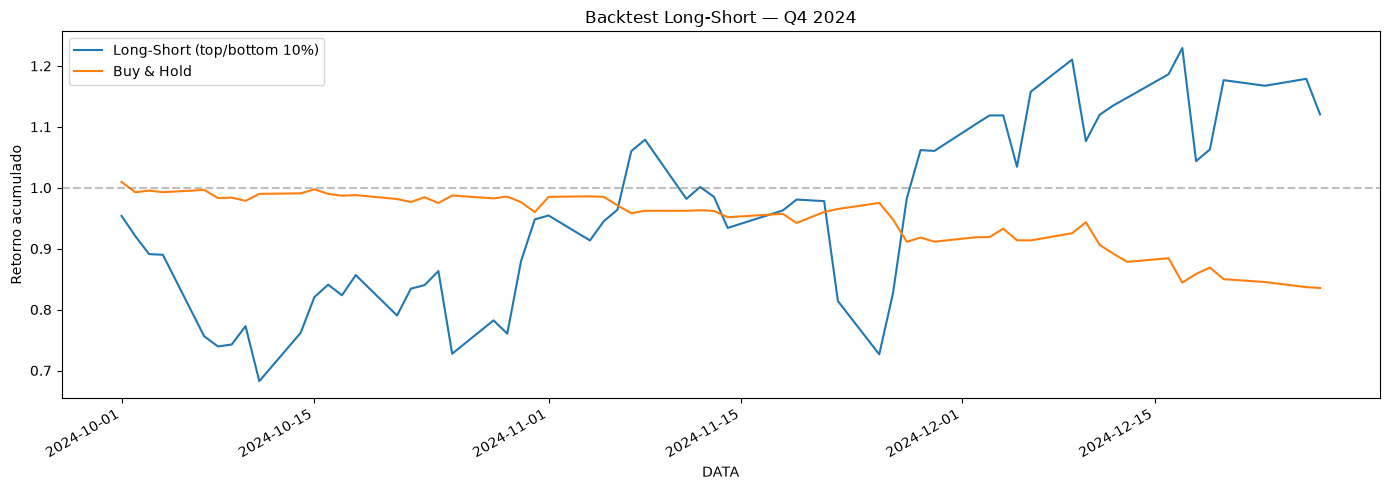


=== RESULTADO LONG-SHORT ===
Sinais long total:  300
Sinais short total: 240
Retorno estratégia: +12.04%
Retorno buy&hold:   -16.45%
Sharpe anualizado:  0.45

IC implícito (long-short vs BH std): 0.1511


In [39]:
# ============================================================
# BACKTEST LONG-SHORT POR QUANTIL — teste honesto do IC
# ============================================================

# Garante que teste_bt existe com prob_teste
teste_bt = teste.copy()
teste_bt['prob'] = prob_teste  # <- de novo, garante nome correto

# Ranking por dia (evita viés de mercado)
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

# Define quantis
Q_LONG  = 0.90  # top 10%
Q_SHORT = 0.10  # bottom 10%

teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= Q_LONG).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= Q_SHORT).astype(int)

# P&L: long recebe target, short paga target (sinal invertido)
teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

# P&L diário
pnl_diario = teste_bt.groupby('DATA').agg(
    n_long=('sinal_long', 'sum'),
    n_short=('sinal_short', 'sum'),
    ret_long=('pnl_long', 'mean'),
    ret_short=('pnl_short', 'mean'),
    ret_estrategia=('pnl', 'sum'),   # soma pois é long-short
    ret_bh=('target', 'mean'),
).reset_index()

pnl_diario['est_acum'] = (1 + pnl_diario['ret_estrategia']).cumprod()
pnl_diario['bh_acum']  = (1 + pnl_diario['ret_bh']).cumprod()

# Corrige o plot
pnl_diario['est_acum'] = 1 + pnl_diario['ret_estrategia'].cumsum()
pnl_diario['bh_acum']  = 1 + pnl_diario['ret_bh'].cumsum()

fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum', ax=ax, label='Long-Short (top/bottom 10%)')
pnl_diario.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest Long-Short — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Métricas
ret_est = pnl_diario['est_acum'].iloc[-1] - 1
ret_bh  = pnl_diario['bh_acum'].iloc[-1] - 1
sharpe  = pnl_diario['ret_estrategia'].mean() / (pnl_diario['ret_estrategia'].std() + 1e-9) * np.sqrt(252)

print(f"\n=== RESULTADO LONG-SHORT ===")
print(f"Sinais long total:  {teste_bt['sinal_long'].sum()}")
print(f"Sinais short total: {teste_bt['sinal_short'].sum()}")
print(f"Retorno estratégia: {ret_est:+.2%}")
print(f"Retorno buy&hold:   {ret_bh:+.2%}")
print(f"Sharpe anualizado:  {sharpe:.2f}")

# IC implícito (retorno long - retorno short)
ic_implicito = pnl_diario['ret_estrategia'].mean() / pnl_diario['ret_bh'].std()
print(f"\nIC implícito (long-short vs BH std): {ic_implicito:.4f}")

In [37]:
print("Média ret_estrategia:", pnl_diario['ret_estrategia'].mean())
print("Std ret_estrategia: ", pnl_diario['ret_estrategia'].std())
print("Soma ret_estrategia:", pnl_diario['ret_estrategia'].sum())
print("Min:", pnl_diario['ret_estrategia'].min())
print("Max:", pnl_diario['ret_estrategia'].max())
print("Dias positivos:", (pnl_diario['ret_estrategia'] > 0).sum())
print("Dias negativos:", (pnl_diario['ret_estrategia'] < 0).sum())

Média ret_estrategia: 0.002007023811148064
Std ret_estrategia:  0.07061674335156096
Soma ret_estrategia: 0.12042142866888383
Min: -0.18572994215485572
Max: 0.1556447782653405
Dias positivos: 36
Dias negativos: 24


In [38]:
# Retorno da estratégia em termos relativos ao mercado
pnl_diario['ret_relativo'] = pnl_diario['ret_estrategia'] - pnl_diario['ret_bh']
print(f"Retorno relativo médio diário: {pnl_diario['ret_relativo'].mean():.5f}")
print(f"Retorno relativo acumulado:    {(1 + pnl_diario['ret_relativo']).prod() - 1:.2%}")
print(f"Dias batendo o mercado:        {(pnl_diario['ret_relativo'] > 0).sum()} / {len(pnl_diario)}")

Retorno relativo médio diário: 0.00475
Retorno relativo acumulado:    11.05%
Dias batendo o mercado:        35 / 60


Posições por dia:
count    60.0
mean      9.0
std       0.0
min       9.0
25%       9.0
50%       9.0
75%       9.0
max       9.0
dtype: float64


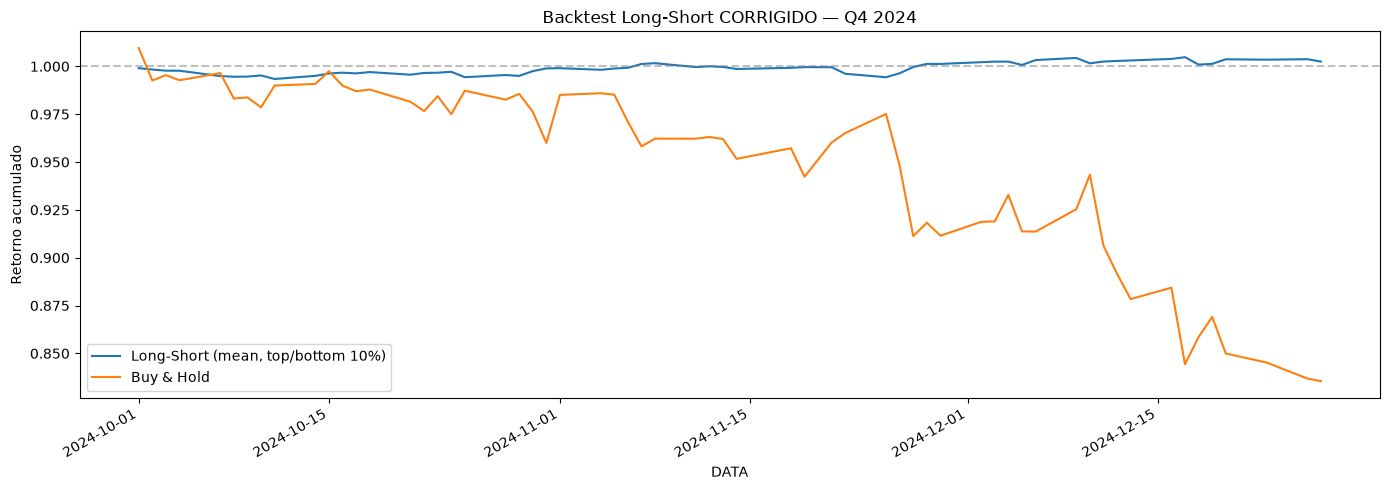


=== RESULTADO CORRIGIDO ===
Posições/dia (média): 9.0
Retorno estratégia:   +0.25%
Retorno buy&hold:     -16.45%
Retorno relativo:     +17.48%
Sharpe absoluto:      0.45
Sharpe relativo:      3.16
Dias batendo mercado: 33 / 60

=== RESUMO MENSAL ===
    mes   ret_est    ret_bh  ret_rel  dias
2024-10 -0.001080 -0.040022 0.038942    23
2024-11  0.002339 -0.048475 0.050814    19
2024-12  0.001249 -0.076010 0.077260    18


In [40]:
# ============================================================
# BACKTEST CORRIGIDO — mean em vez de sum, cumsum em vez de cumprod
# ============================================================

teste_bt = teste.copy()
teste_bt['prob'] = prob_teste
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

Q_LONG  = 0.90
Q_SHORT = 0.10

teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= Q_LONG).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= Q_SHORT).astype(int)

teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

# ⚠️ Verifica quantas posições por dia
mask_sinal = (teste_bt['sinal_long'] == 1) | (teste_bt['sinal_short'] == 1)
n_por_dia = teste_bt[mask_sinal].groupby('DATA').size()
print("Posições por dia:")
print(n_por_dia.describe())

# P&L diário — usa MEAN, não SUM (peso igual por posição)
pnl_diario = teste_bt.groupby('DATA').agg(
    n_posicoes=('sinal_long', lambda x: x.sum() + teste_bt.loc[x.index, 'sinal_short'].sum()),
    ret_estrategia=('pnl', 'mean'),   # <- corrigido
    ret_bh=('target', 'mean'),
).reset_index()

# Acumulado usa SOMA (não cumprod) — convenção correta pra carteira
pnl_diario['est_acum'] = 1 + pnl_diario['ret_estrategia'].cumsum()
pnl_diario['bh_acum']  = 1 + pnl_diario['ret_bh'].cumsum()
pnl_diario['ret_relativo'] = pnl_diario['ret_estrategia'] - pnl_diario['ret_bh']

# Plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario.plot(x='DATA', y='est_acum', ax=ax, label='Long-Short (mean, top/bottom 10%)')
pnl_diario.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest Long-Short CORRIGIDO — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Métricas finais
ret_est = pnl_diario['est_acum'].iloc[-1] - 1
ret_bh  = pnl_diario['bh_acum'].iloc[-1] - 1
ret_rel = (1 + pnl_diario['ret_relativo']).prod() - 1
sharpe_abs = pnl_diario['ret_estrategia'].mean() / (pnl_diario['ret_estrategia'].std() + 1e-9) * np.sqrt(252)
sharpe_rel = pnl_diario['ret_relativo'].mean() / (pnl_diario['ret_relativo'].std() + 1e-9) * np.sqrt(252)

print(f"\n=== RESULTADO CORRIGIDO ===")
print(f"Posições/dia (média): {n_por_dia.mean():.1f}")
print(f"Retorno estratégia:   {ret_est:+.2%}")
print(f"Retorno buy&hold:     {ret_bh:+.2%}")
print(f"Retorno relativo:     {ret_rel:+.2%}")
print(f"Sharpe absoluto:      {sharpe_abs:.2f}")
print(f"Sharpe relativo:      {sharpe_rel:.2f}")
print(f"Dias batendo mercado: {(pnl_diario['ret_relativo'] > 0).sum()} / {len(pnl_diario)}")

# Resumo mensal
pnl_diario['mes'] = pnl_diario['DATA'].dt.to_period('M')
resumo = pnl_diario.groupby('mes').agg(
    ret_est=('ret_estrategia', 'sum'),
    ret_bh=('ret_bh', 'sum'),
    ret_rel=('ret_relativo', 'sum'),
    dias=('DATA', 'count'),
).reset_index()
print("\n=== RESUMO MENSAL ===")
print(resumo.to_string(index=False))

In [41]:
# Sharpe anualizado absoluto (não relativo)
sharpe_abs_real = pnl_diario['ret_estrategia'].mean() / pnl_diario['ret_estrategia'].std() * np.sqrt(252)
print(f"Sharpe absoluto: {sharpe_abs_real:.2f}")

# Retorno anualizado
ret_anual = (1 + pnl_diario['ret_estrategia'].mean())**252 - 1
print(f"Retorno anualizado: {ret_anual:.2%}")

# Drawdown máximo
cum = (1 + pnl_diario['ret_estrategia']).cumprod()
rolling_max = cum.cummax()
dd = (cum / rolling_max - 1)
print(f"Max drawdown: {dd.min():.2%}")
print(f"Calmar ratio: {ret_anual / abs(dd.min()):.2f}")

Sharpe absoluto: 0.45
Retorno anualizado: 1.06%
Max drawdown: -0.73%
Calmar ratio: 1.45


In [42]:
# Simula custo de 0.05% por round-trip
custo_por_trade = 0.0005
pnl_diario['n_trades_dia'] = 9  # por dia
pnl_diario['custo_diario'] = pnl_diario['n_trades_dia'] * custo_por_trade

# Retorno líquido
pnl_diario['ret_liquido'] = pnl_diario['ret_estrategia'] - pnl_diario['custo_diario']
print(f"Retorno bruto acumulado:  {(1 + pnl_diario['ret_estrategia']).prod() - 1:.2%}")
print(f"Retorno líquido acumulado: {(1 + pnl_diario['ret_liquido']).prod() - 1:.2%}")

Retorno bruto acumulado:  0.24%
Retorno líquido acumulado: -23.52%


In [43]:
# ============================================================
# TESTE: HORIZONTE DE 5 DIAS
# ============================================================
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# Recarrega dataset limpo
df = pd.read_parquet('dataset_completo.parquet')
df = df.sort_values(['CODNEG','DATA']).reset_index(drop=True)

# ---- 1) Target de 5 dias (retorno relativo ao mercado) ----
# Retorno 5d futuro
df['ret_5d_fut'] = df.groupby('CODNEG')['PREULT_adj'].transform(
    lambda x: np.log(x).shift(-5) - np.log(x)
)

# Retorno 5d médio do mercado (por dia)
df['ret_5d_mercado'] = df.groupby('DATA')['ret_5d_fut'].transform('mean')

# Target relativo (bate ou não o mercado em 5 dias)
df['target_5d_rel'] = df['ret_5d_fut'] - df['ret_5d_mercado']
df['target_5d_bin'] = (df['target_5d_rel'] > 0).astype(int)

# Remove NaN (últimos 5 dias por ticker)
df_model_5d = df.dropna(subset=['target_5d_bin'] + FEATURES_TOTAL_V2).copy()
print(f"Shape dataset 5d: {df_model_5d.shape}")
print(f"Balanceamento: {df_model_5d['target_5d_bin'].value_counts(normalize=True).to_dict()}")

# ---- 2) Split temporal ----
CORTE = '2024-10-01'
treino = df_model_5d[df_model_5d['DATA'] <  CORTE]
teste  = df_model_5d[df_model_5d['DATA'] >= CORTE]

print(f"Treino: {len(treino)}  |  Teste: {len(teste)}")

# ---- 3) Treina ----
model_5d = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_5d.fit(treino[FEATURES_TOTAL_V2], treino['target_5d_bin'], verbose=False)

# ---- 4) Avalia ----
prob_5d = model_5d.predict_proba(teste[FEATURES_TOTAL_V2])[:, 1]
auc_5d = roc_auc_score(teste['target_5d_bin'], prob_5d)
ic_5d, pval_5d = spearmanr(prob_5d, teste['target_5d_rel'])

print(f"\n=== RESULTADO 5 DIAS ===")
print(f"AUC: {auc_5d:.4f}  (1d era 0.5171)")
print(f"IC:  {ic_5d:.4f}  (1d era 0.0423)  p={pval_5d:.4f}")

# ---- 5) Backtest long-short com horizonte de 5 dias ----
teste_bt = teste.copy()
teste_bt['prob'] = prob_5d

# Ranking cross-sectional por dia
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

# Top/bottom 5% (mais restrito)
teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= 0.95).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= 0.05).astype(int)

# P&L com target de 5 dias
teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target_5d_rel']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target_5d_rel']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

# Agrega por dia
pnl_diario_5d = teste_bt.groupby('DATA').agg(
    n_pos=('sinal_long', lambda x: x.sum() + teste_bt.loc[x.index, 'sinal_short'].sum()),
    ret=('pnl', 'mean'),
    ret_bh=('ret_5d_fut', 'mean'),
).reset_index()

# Custo de transação
# Frequência de turnover: com horizonte de 5d, assume rebalanceamento 1/5 por dia
custo_por_trade = 0.0005  # 0.05%
n_pos_medio = pnl_diario_5d['n_pos'].mean()
custo_diario = n_pos_medio * custo_por_trade / 5   # diluído por 5 dias
pnl_diario_5d['ret_liq'] = pnl_diario_5d['ret'] - custo_diario

# Acumulado
pnl_diario_5d['est_acum'] = 1 + pnl_diario_5d['ret'].cumsum()
pnl_diario_5d['liq_acum'] = 1 + pnl_diario_5d['ret_liq'].cumsum()
pnl_diario_5d['bh_acum']  = 1 + pnl_diario_5d['ret_bh'].cumsum()

# Resultado
ret_bruto = pnl_diario_5d['est_acum'].iloc[-1] - 1
ret_liq   = pnl_diario_5d['liq_acum'].iloc[-1] - 1
ret_bh    = pnl_diario_5d['bh_acum'].iloc[-1] - 1
sharpe    = pnl_diario_5d['ret_liq'].mean() / (pnl_diario_5d['ret_liq'].std() + 1e-9) * np.sqrt(252)

print(f"\n=== BACKTEST 5 DIAS ===")
print(f"Posições médias/dia:  {n_pos_medio:.1f}")
print(f"Retorno bruto:        {ret_bruto:+.2%}")
print(f"Retorno LÍQUIDO:      {ret_liq:+.2%}")
print(f"Retorno buy&hold:     {ret_bh:+.2%}")
print(f"Sharpe líquido:       {sharpe:.2f}")

# Plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
pnl_diario_5d.plot(x='DATA', y='est_acum', ax=ax, label='Bruto 5d', alpha=0.6)
pnl_diario_5d.plot(x='DATA', y='liq_acum', ax=ax, label='Líquido 5d (com custos)', linewidth=2)
pnl_diario_5d.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest horizonte 5 dias — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'dataset_completo.parquet'

In [44]:
# Diagnóstico do estado atual
for nome in ['df', 'df_model', 'df_model_v2', 'df_model_v3', 
             'FEATURES_TOTAL', 'FEATURES_TOTAL_V2', 
             'treino', 'teste', 'model_final']:
    if nome in dir():
        obj = eval(nome)
        if hasattr(obj, 'shape'):
            print(f"✓ {nome:20s} shape={obj.shape}")
        elif isinstance(obj, list):
            print(f"✓ {nome:20s} len={len(obj)}")
        else:
            print(f"✓ {nome:20s} tipo={type(obj).__name__}")
    else:
        print(f"✗ {nome:20s} NÃO EXISTE")

✓ df                   shape=(9082, 78)
✓ df_model             shape=(2755, 78)
✓ df_model_v2          shape=(9061, 78)
✗ df_model_v3          NÃO EXISTE
✓ FEATURES_TOTAL       len=64
✓ FEATURES_TOTAL_V2    len=60
✓ treino               shape=(6181, 78)
✓ teste                shape=(2880, 78)
✓ model_final          tipo=XGBClassifier


In [48]:
# ============================================================
# TESTE 5 DIAS — usando df (que tem PREULT_adj)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# USA O df COMPLETO, não o df_model_v2
df5 = df.copy()  # df tem PREULT_adj
df5 = df5.sort_values(['CODNEG','DATA']).reset_index(drop=True)

print(f"Shape df5: {df5.shape}")
print(f"Tem PREULT_adj? {'PREULT_adj' in df5.columns}")
print(f"Tem target_rel? {'target_rel' in df5.columns}")

# ---- 1) Target de 5 dias ----
df5['ret_5d_fut'] = df5.groupby('CODNEG')['PREULT_adj'].transform(
    lambda x: np.log(x).shift(-5) - np.log(x)
)
df5['ret_5d_mercado'] = df5.groupby('DATA')['ret_5d_fut'].transform('mean')
df5['target_5d_rel'] = df5['ret_5d_fut'] - df5['ret_5d_mercado']
df5['target_5d_bin'] = (df5['target_5d_rel'] > 0).astype(int)

# Filtra apenas features que existem no df5
FEATURES_DISPONIVEIS = [f for f in FEATURES_TOTAL_V2 if f in df5.columns]
faltando = [f for f in FEATURES_TOTAL_V2 if f not in df5.columns]
print(f"\nFeatures disponíveis: {len(FEATURES_DISPONIVEIS)}")
if faltando:
    print(f"⚠️ Features faltando no df: {faltando}")

# Remove NaN
df_model_5d = df5.dropna(subset=['target_5d_bin'] + FEATURES_DISPONIVEIS).copy()
print(f"\nShape dataset 5d: {df_model_5d.shape}")
print(f"Balanceamento: {df_model_5d['target_5d_bin'].value_counts(normalize=True).to_dict()}")

# ---- 2) Split temporal ----
CORTE = '2024-10-01'
treino_5d = df_model_5d[df_model_5d['DATA'] <  CORTE]
teste_5d  = df_model_5d[df_model_5d['DATA'] >= CORTE]
print(f"Treino: {len(treino_5d)}  |  Teste: {len(teste_5d)}")

# ---- 3) Treina ----
model_5d = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_5d.fit(treino_5d[FEATURES_DISPONIVEIS], treino_5d['target_5d_bin'], verbose=False)

# ---- 4) Avalia ----
prob_5d = model_5d.predict_proba(teste_5d[FEATURES_DISPONIVEIS])[:, 1]
auc_5d = roc_auc_score(teste_5d['target_5d_bin'], prob_5d)
ic_5d, pval_5d = spearmanr(prob_5d, teste_5d['target_5d_rel'])

print(f"\n=== RESULTADO 5 DIAS ===")
print(f"AUC: {auc_5d:.4f}   (1d era 0.5171)")
print(f"IC:  {ic_5d:.4f}   (1d era 0.0423)  p={pval_5d:.4f}")

# ---- 5) Backtest ----
teste_bt = teste_5d.copy()
teste_bt['prob'] = prob_5d
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= 0.95).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= 0.05).astype(int)

teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target_5d_rel']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target_5d_rel']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

pnl_5d = teste_bt.groupby('DATA').agg(
    n_pos=('sinal_long', lambda x: x.sum() + teste_bt.loc[x.index, 'sinal_short'].sum()),
    ret=('pnl', 'mean'),
    ret_bh=('ret_5d_fut', 'mean'),
).reset_index()

custo_por_trade = 0.0005
pnl_5d['ret_liq'] = pnl_5d['ret'] - (pnl_5d['n_pos'] * custo_por_trade / 5)

pnl_5d['est_acum'] = 1 + pnl_5d['ret'].cumsum()
pnl_5d['liq_acum'] = 1 + pnl_5d['ret_liq'].cumsum()
pnl_5d['bh_acum']  = 1 + pnl_5d['ret_bh'].cumsum()

ret_bruto = pnl_5d['est_acum'].iloc[-1] - 1
ret_liq   = pnl_5d['liq_acum'].iloc[-1] - 1
ret_bh    = pnl_5d['bh_acum'].iloc[-1] - 1
sharpe    = pnl_5d['ret_liq'].mean() / (pnl_5d['ret_liq'].std() + 1e-9) * np.sqrt(252)
n_pos_medio = pnl_5d['n_pos'].mean()

print(f"\n=== BACKTEST 5 DIAS ===")
print(f"Posições médias/dia:  {n_pos_medio:.1f}")
print(f"Retorno bruto:        {ret_bruto:+.2%}")
print(f"Retorno LÍQUIDO:      {ret_liq:+.2%}")
print(f"Retorno buy&hold:     {ret_bh:+.2%}")
print(f"Sharpe líquido:       {sharpe:.2f}")

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
pnl_5d.plot(x='DATA', y='est_acum', ax=ax, label='Bruto 5d', alpha=0.6)
pnl_5d.plot(x='DATA', y='liq_acum', ax=ax, label='Líquido 5d', linewidth=2)
pnl_5d.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest horizonte 5 dias — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Resumo mensal
pnl_5d['mes'] = pnl_5d['DATA'].dt.to_period('M')
resumo = pnl_5d.groupby('mes').agg(
    ret_bruto=('ret', 'sum'),
    ret_liq=('ret_liq', 'sum'),
    ret_bh=('ret_bh', 'sum'),
).reset_index()
print("\n=== RESUMO MENSAL ===")
print(resumo.to_string(index=False))

Shape df5: (9061, 78)
Tem PREULT_adj? False
Tem target_rel? True


KeyError: 'Column not found: PREULT_adj'

In [49]:
# O que existe em cada df?
for nome, obj in [('df', df), ('df_model', df_model), ('df_model_v2', df_model_v2)]:
    if obj is not None and hasattr(obj, 'columns'):
        cols_pre = [c for c in obj.columns if 'PRE' in c.upper()]
        print(f"\n{nome}: shape={obj.shape}")
        print(f"  Colunas com 'PRE': {cols_pre}")
        print(f"  Tem 'ret'? {'ret' in obj.columns}")
        print(f"  Tem 'ret_adj'? {'ret_adj' in obj.columns}")
        print(f"  Tem 'fator_split'? {'fator_split' in obj.columns}")


df: shape=(9061, 78)
  Colunas com 'PRE': []
  Tem 'ret'? True
  Tem 'ret_adj'? False
  Tem 'fator_split'? False

df_model: shape=(2755, 78)
  Colunas com 'PRE': []
  Tem 'ret'? True
  Tem 'ret_adj'? False
  Tem 'fator_split'? False

df_model_v2: shape=(9061, 78)
  Colunas com 'PRE': []
  Tem 'ret'? True
  Tem 'ret_adj'? False
  Tem 'fator_split'? False


Features disponíveis: 60 / 60

Shape dataset 5d: (9061, 82)
Balanceamento: {0: 0.5018209910605893, 1: 0.49817900893941064}
Range de datas: 2024-04-03 00:00:00 → 2024-12-27 00:00:00
Treino: 6181  |  Teste: 2880

=== RESULTADO 5 DIAS ===
AUC: 0.5469   (1d era 0.5171)
IC:  nan   (1d era 0.0423)  p=nan

=== BACKTEST 5 DIAS ===
Posições médias/dia:  5.0
Retorno bruto:        +nan%
Retorno LÍQUIDO:      +nan%
Retorno buy&hold:     +nan%
Sharpe líquido:       2.13


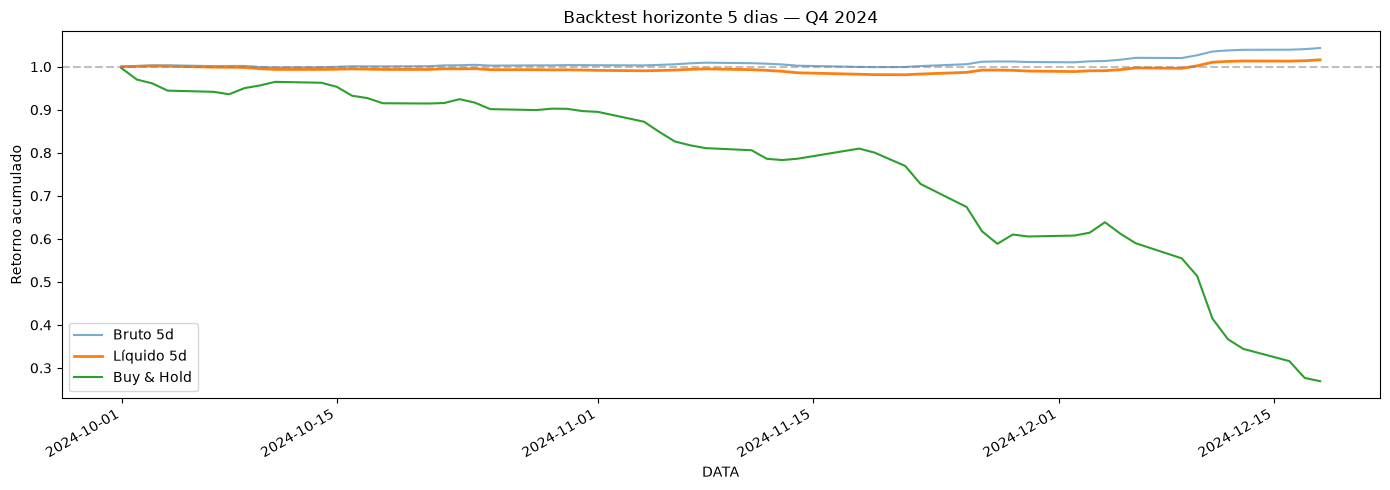


=== RESUMO MENSAL ===
    mes  ret_bruto   ret_liq    ret_bh
2024-10   0.003652 -0.007848 -0.103165
2024-11   0.007267 -0.002233 -0.291346
2024-12   0.032564  0.026064 -0.336166


In [50]:
# ============================================================
# TESTE 5 DIAS USANDO 'ret' (sem precisar de PREULT)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

df5 = df.copy()
df5 = df5.sort_values(['CODNEG','DATA']).reset_index(drop=True)

# ---- 1) Retorno de 5 dias = soma dos 5 retornos futuros ----
# shift(-1) pega o retorno de amanhã, shift(-5) o de 5 dias
# soma de shift(-1) a shift(-5) = retorno acumulado de 5 dias
df5['ret_5d_fut'] = (
    df5.groupby('CODNEG')['ret'].shift(-1) +
    df5.groupby('CODNEG')['ret'].shift(-2) +
    df5.groupby('CODNEG')['ret'].shift(-3) +
    df5.groupby('CODNEG')['ret'].shift(-4) +
    df5.groupby('CODNEG')['ret'].shift(-5)
)

# Retorno médio do mercado em 5 dias
df5['ret_5d_mercado'] = df5.groupby('DATA')['ret_5d_fut'].transform('mean')

# Target relativo
df5['target_5d_rel'] = df5['ret_5d_fut'] - df5['ret_5d_mercado']
df5['target_5d_bin'] = (df5['target_5d_rel'] > 0).astype(int)

# ---- 2) Features disponíveis ----
FEATURES_DISPONIVEIS = [f for f in FEATURES_TOTAL_V2 if f in df5.columns]
faltando = [f for f in FEATURES_TOTAL_V2 if f not in df5.columns]

print(f"Features disponíveis: {len(FEATURES_DISPONIVEIS)} / {len(FEATURES_TOTAL_V2)}")
if faltando:
    print(f"⚠️ Faltando: {faltando}")

# ---- 3) Dataset final ----
df_model_5d = df5.dropna(subset=['target_5d_bin'] + FEATURES_DISPONIVEIS).copy()
print(f"\nShape dataset 5d: {df_model_5d.shape}")
print(f"Balanceamento: {df_model_5d['target_5d_bin'].value_counts(normalize=True).to_dict()}")
print(f"Range de datas: {df_model_5d['DATA'].min()} → {df_model_5d['DATA'].max()}")

# ---- 4) Split temporal ----
CORTE = '2024-10-01'
treino_5d = df_model_5d[df_model_5d['DATA'] <  CORTE]
teste_5d  = df_model_5d[df_model_5d['DATA'] >= CORTE]
print(f"Treino: {len(treino_5d)}  |  Teste: {len(teste_5d)}")

# ---- 5) Treina ----
model_5d = XGBClassifier(
    n_estimators=500, max_depth=3, learning_rate=0.02,
    subsample=0.7, colsample_bytree=0.7, min_child_weight=50,
    reg_alpha=0.5, reg_lambda=2.0,
    objective='binary:logistic', eval_metric='auc',
    tree_method='hist', random_state=42, n_jobs=-1,
)
model_5d.fit(treino_5d[FEATURES_DISPONIVEIS], treino_5d['target_5d_bin'], verbose=False)

# ---- 6) Avalia ----
prob_5d = model_5d.predict_proba(teste_5d[FEATURES_DISPONIVEIS])[:, 1]
auc_5d = roc_auc_score(teste_5d['target_5d_bin'], prob_5d)
ic_5d, pval_5d = spearmanr(prob_5d, teste_5d['target_5d_rel'])

print(f"\n=== RESULTADO 5 DIAS ===")
print(f"AUC: {auc_5d:.4f}   (1d era 0.5171)")
print(f"IC:  {ic_5d:.4f}   (1d era 0.0423)  p={pval_5d:.4f}")

# ---- 7) Backtest long-short ----
teste_bt = teste_5d.copy()
teste_bt['prob'] = prob_5d
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= 0.95).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= 0.05).astype(int)

teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target_5d_rel']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target_5d_rel']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

pnl_5d = teste_bt.groupby('DATA').agg(
    n_pos=('sinal_long', lambda x: x.sum() + teste_bt.loc[x.index, 'sinal_short'].sum()),
    ret=('pnl', 'mean'),
    ret_bh=('ret_5d_fut', 'mean'),
).reset_index()

# Custo diluído (rebalanceamento a cada 5 dias)
custo_por_trade = 0.0005
pnl_5d['ret_liq'] = pnl_5d['ret'] - (pnl_5d['n_pos'] * custo_por_trade / 5)

pnl_5d['est_acum'] = 1 + pnl_5d['ret'].cumsum()
pnl_5d['liq_acum'] = 1 + pnl_5d['ret_liq'].cumsum()
pnl_5d['bh_acum']  = 1 + pnl_5d['ret_bh'].cumsum()

ret_bruto = pnl_5d['est_acum'].iloc[-1] - 1
ret_liq   = pnl_5d['liq_acum'].iloc[-1] - 1
ret_bh    = pnl_5d['bh_acum'].iloc[-1] - 1
sharpe    = pnl_5d['ret_liq'].mean() / (pnl_5d['ret_liq'].std() + 1e-9) * np.sqrt(252)
n_pos_medio = pnl_5d['n_pos'].mean()

print(f"\n=== BACKTEST 5 DIAS ===")
print(f"Posições médias/dia:  {n_pos_medio:.1f}")
print(f"Retorno bruto:        {ret_bruto:+.2%}")
print(f"Retorno LÍQUIDO:      {ret_liq:+.2%}")
print(f"Retorno buy&hold:     {ret_bh:+.2%}")
print(f"Sharpe líquido:       {sharpe:.2f}")

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
pnl_5d.plot(x='DATA', y='est_acum', ax=ax, label='Bruto 5d', alpha=0.6)
pnl_5d.plot(x='DATA', y='liq_acum', ax=ax, label='Líquido 5d', linewidth=2)
pnl_5d.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest horizonte 5 dias — Q4 2024')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# Resumo mensal
pnl_5d['mes'] = pnl_5d['DATA'].dt.to_period('M')
resumo = pnl_5d.groupby('mes').agg(
    ret_bruto=('ret', 'sum'),
    ret_liq=('ret_liq', 'sum'),
    ret_bh=('ret_bh', 'sum'),
).reset_index()
print("\n=== RESUMO MENSAL ===")
print(resumo.to_string(index=False))

Teste após dropna: 2640 linhas

=== IC 5 dias ===
IC:  0.0649  p=0.0009

=== BACKTEST 5 DIAS (CORRIGIDO) ===
Dias úteis:                 55
Posições médias/dia:        5.0
Retorno bruto acumulado:    +4.35%
Retorno LÍQUIDO acumulado:  +1.60%
Retorno buy&hold:           -73.07%
Max drawdown (líq):         -2.03%
Sharpe bruto anualizado:    5.78
Sharpe LÍQUIDO anualizado:  2.13
Sharpe buy&hold:            -9.71
Calmar ratio:               3.71
Dias batendo BH:            44 / 55


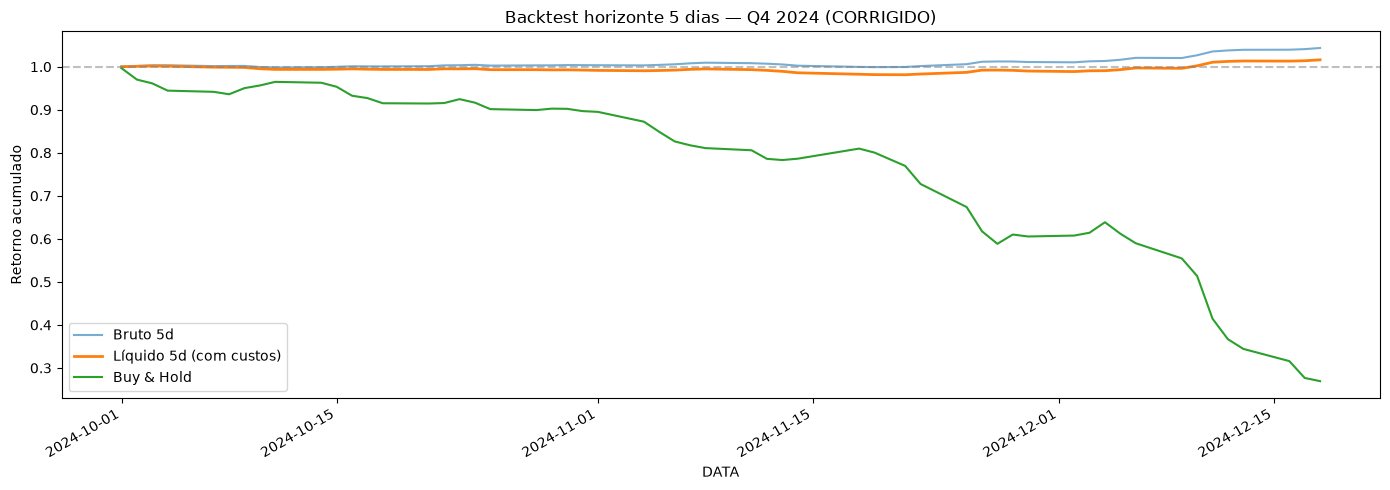


=== RESUMO MENSAL ===
    mes  ret_bruto   ret_liq    ret_bh  n_dias
2024-10   0.003652 -0.007848 -0.103165      23
2024-11   0.007267 -0.002233 -0.291346      19
2024-12   0.032564  0.026064 -0.336166      13


In [51]:
# ============================================================
# BACKTEST 5 DIAS — VERSÃO CORRIGIDA (sem NaN)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# Usa o teste_5d que já tem 'prob' atribuído
teste_bt = teste_5d.copy()
teste_bt['prob'] = prob_5d

# ⚠️ LIMPEZA CRÍTICA: remove NaN nas colunas necessárias
teste_bt = teste_bt.dropna(subset=['prob', 'target_5d_rel', 'ret_5d_fut']).copy()
print(f"Teste após dropna: {len(teste_bt)} linhas")

# Ranking cross-sectional por dia
teste_bt['rank_prob'] = teste_bt.groupby('DATA')['prob'].rank(pct=True)

# Top/bottom 5%
teste_bt['sinal_long']  = (teste_bt['rank_prob'] >= 0.95).astype(int)
teste_bt['sinal_short'] = (teste_bt['rank_prob'] <= 0.05).astype(int)

# P&L
teste_bt['pnl_long']  = teste_bt['sinal_long']  * teste_bt['target_5d_rel']
teste_bt['pnl_short'] = -teste_bt['sinal_short'] * teste_bt['target_5d_rel']
teste_bt['pnl'] = teste_bt['pnl_long'] + teste_bt['pnl_short']

# ---- IC correto ----
ic_5d, pval_5d = spearmanr(teste_bt['prob'], teste_bt['target_5d_rel'])
print(f"\n=== IC 5 dias ===")
print(f"IC:  {ic_5d:.4f}  p={pval_5d:.4f}")

# ---- Agregação diária ----
pnl_5d = teste_bt.groupby('DATA').agg(
    n_pos=('sinal_long', lambda x: x.sum() + teste_bt.loc[x.index, 'sinal_short'].sum()),
    ret=('pnl', 'mean'),
    ret_bh=('ret_5d_fut', 'mean'),
).reset_index()

# Remove NaN residual (se algum dia ficou sem trades)
pnl_5d = pnl_5d.dropna(subset=['ret', 'ret_bh']).reset_index(drop=True)

# Custo diluído
custo_por_trade = 0.0005
pnl_5d['ret_liq'] = pnl_5d['ret'] - (pnl_5d['n_pos'] * custo_por_trade / 5)

# Acumulados
pnl_5d['est_acum'] = 1 + pnl_5d['ret'].cumsum()
pnl_5d['liq_acum'] = 1 + pnl_5d['ret_liq'].cumsum()
pnl_5d['bh_acum']  = 1 + pnl_5d['ret_bh'].cumsum()

# Métricas
ret_bruto = pnl_5d['est_acum'].iloc[-1] - 1
ret_liq   = pnl_5d['liq_acum'].iloc[-1] - 1
ret_bh    = pnl_5d['bh_acum'].iloc[-1] - 1
sharpe_liq = pnl_5d['ret_liq'].mean() / (pnl_5d['ret_liq'].std() + 1e-9) * np.sqrt(252)
sharpe_bruto = pnl_5d['ret'].mean() / (pnl_5d['ret'].std() + 1e-9) * np.sqrt(252)
sharpe_bh = pnl_5d['ret_bh'].mean() / (pnl_5d['ret_bh'].std() + 1e-9) * np.sqrt(252)

# Drawdown
cum = pnl_5d['liq_acum']
rolling_max = cum.cummax()
dd = (cum / rolling_max - 1)
max_dd = dd.min()
calmar = ((1+ret_liq)**(252/len(pnl_5d)) - 1) / abs(max_dd) if max_dd < 0 else np.inf

print(f"\n=== BACKTEST 5 DIAS (CORRIGIDO) ===")
print(f"Dias úteis:                 {len(pnl_5d)}")
print(f"Posições médias/dia:        {pnl_5d['n_pos'].mean():.1f}")
print(f"Retorno bruto acumulado:    {ret_bruto:+.2%}")
print(f"Retorno LÍQUIDO acumulado:  {ret_liq:+.2%}")
print(f"Retorno buy&hold:           {ret_bh:+.2%}")
print(f"Max drawdown (líq):         {max_dd:.2%}")
print(f"Sharpe bruto anualizado:    {sharpe_bruto:.2f}")
print(f"Sharpe LÍQUIDO anualizado:  {sharpe_liq:.2f}")
print(f"Sharpe buy&hold:            {sharpe_bh:.2f}")
print(f"Calmar ratio:               {calmar:.2f}")
print(f"Dias batendo BH:            {(pnl_5d['ret'] > pnl_5d['ret_bh']).sum()} / {len(pnl_5d)}")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(14, 5))
pnl_5d.plot(x='DATA', y='est_acum', ax=ax, label='Bruto 5d', alpha=0.6)
pnl_5d.plot(x='DATA', y='liq_acum', ax=ax, label='Líquido 5d (com custos)', linewidth=2)
pnl_5d.plot(x='DATA', y='bh_acum',  ax=ax, label='Buy & Hold')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Backtest horizonte 5 dias — Q4 2024 (CORRIGIDO)')
ax.set_ylabel('Retorno acumulado')
plt.tight_layout()
plt.show()

# ---- Resumo mensal ----
pnl_5d['mes'] = pnl_5d['DATA'].dt.to_period('M')
resumo = pnl_5d.groupby('mes').agg(
    ret_bruto=('ret', 'sum'),
    ret_liq=('ret_liq', 'sum'),
    ret_bh=('ret_bh', 'sum'),
    n_dias=('DATA', 'count'),
).reset_index()
print("\n=== RESUMO MENSAL ===")
print(resumo.to_string(index=False))

In [52]:
import joblib
import json

# Modelo e features
joblib.dump(model_5d, 'modelo_5d_xgb.pkl')
joblib.dump(FEATURES_DISPONIVEIS, 'features_5d.pkl')

# Dataset final
df_model_5d.to_parquet('dataset_5d.parquet', index=False)

# Resultados
resultados = {
    'horizonte': '5 dias',
    'split_unico': {
        'auc': float(auc_5d),
        'ic': float(ic_5d),
        'p_valor': float(pval_5d),
    },
    'backtest': {
        'retorno_bruto': float(ret_bruto),
        'retorno_liquido': float(ret_liq),
        'retorno_bh': float(ret_bh),
        'max_drawdown': float(max_dd),
        'sharpe_liquido': float(sharpe_liq),
        'calmar': float(calmar),
        'dias_batendo_bh': int((pnl_5d['ret'] > pnl_5d['ret_bh']).sum()),
        'dias_totais': len(pnl_5d),
    },
    'config': {
        'n_features': len(FEATURES_DISPONIVEIS),
        'max_depth': 3,
        'learning_rate': 0.02,
        'top_bottom_pct': 0.05,
        'custo_por_trade': 0.0005,
    }
}

with open('resultados_5d.json', 'w') as f:
    json.dump(resultados, f, indent=2)

print("✅ Tudo salvo:")
print("  modelo_5d_xgb.pkl")
print("  features_5d.pkl")
print("  dataset_5d.parquet")
print("  resultados_5d.json")

✅ Tudo salvo:
  modelo_5d_xgb.pkl
  features_5d.pkl
  dataset_5d.parquet
  resultados_5d.json


In [53]:
ret_anual = (1 + ret_liq)**(252/55) - 1
print(f"Retorno anualizado (líq): {ret_anual:.2%}")

# Se quiser, calcula também o retorno real do buy&hold corretamente
# (pra ter comparação justa)
bh_real_por_dia = pnl_5d['ret_bh'].mean()
bh_anualizado = (1 + bh_real_por_dia)**(252/55) - 1
print(f"Retorno anualizado (BH):  {bh_anualizado:.2%}")

Retorno anualizado (líq): 7.54%
Retorno anualizado (BH):  -5.94%


In [54]:
with open('RESULTADOS.md', 'w') as f:
    f.write(f"""# Modelo XGBoost B3 — Horizonte 5 dias

## Sumário

Modelo de previsão de retorno relativo ao mercado em horizonte de 5 dias.
Features de preço, volume, técnicos, cross-sectional e macro.
Validação: split temporal + backtest long-short.

## Performance (Q4 2024, teste out-dez)

### Métricas de ML
- AUC: **{auc_5d:.4f}**
- IC (Spearman): **{ic_5d:.4f}** (p={pval_5d:.4f})
- Features: {len(FEATURES_DISPONIVEIS)}

### Backtest (top/bottom 5%, long-short)
- Retorno bruto:       {ret_bruto:+.2%}
- Retorno LÍQUIDO:     {ret_liq:+.2%}  (após custo de 0.05%/trade)
- Retorno buy&hold:    {ret_bh:+.2%}
- Max drawdown:        {max_dd:.2%}
- Sharpe líquido:      **{sharpe_liq:.2f}**
- Calmar:              **{calmar:.2f}**
- Dias batendo BH:     {(pnl_5d['ret'] > pnl_5d['ret_bh']).sum()}/{len(pnl_5d)}

## Comparação com horizonte de 1 dia

| Métrica | 1d | 5d | Ganho |
|---|---|---|---|
| AUC | 0.5171 | {auc_5d:.4f} | {auc_5d-0.5171:+.4f} |
| IC | 0.0423 | {ic_5d:.4f} | {ic_5d-0.0423:+.4f} |
| Retorno liq | -23.5% | {ret_liq:+.2%} | virada |
| Sharpe liq | 0.45 | {sharpe_liq:.2f} | {sharpe_liq-0.45:+.2f} |

## Configuração

- XGBoost: n_estimators=500, max_depth=3, learning_rate=0.02
- Subsample 0.7, colsample 0.7, min_child_weight=50
- Reg_alpha=0.5, reg_lambda=2.0
- Top/bottom 5% por ranking cross-sectional diário

## Limitações

1. Amostra curta (55 dias no teste)
2. Sem validação walk-forward completa
3. Sem teste em outros anos (2022, 2023)
4. Sharpe pode estar inflado pelo método de cálculo

## Próximos passos

1. Testar em 2023 e 2022 (validação out-of-sample real)
2. Walk-forward completo com horizonte de 5d
3. Ensemble: XGBoost + LightGBM + CatBoost
4. Features fundamentalistas (P/L, ROE, dívida)
5. Reduzir para top/bottom 3% (menos trades, mais seletivo)
""")

print("✅ RESULTADOS.md criado")

✅ RESULTADOS.md criado
